# FitCore — Member Churn Prediction
## End-to-End ML Notebook

**Project:** FitCore Gym Business Automation, Intelligence & Prediction System  
**ML objective:** Identify members who are at risk of churning.

### Notebook philosophy
This notebook is designed for a real project rather than a Kaggle-only workflow:

**PostgreSQL → data inspection → target definition → feature engineering → EDA → split → preprocessing → baseline → model comparison → evaluation → explainability → prediction output**

> **Important:** The notebook does **not** assume that every column exists in the FitCore database. The first sections inspect the real schema and the later feature-building logic adapts to available columns. Review the generated feature table and target definition before treating the results as final.

### Suggested churn definition
For this first version, churn should be defined using a **future observation window**, not by using information that would only be known after the prediction date.

A practical starting point is:

> A member is considered churned if they have no attendance/activity for a defined period after the observation cutoff, subject to the membership data available in FitCore.

The exact window must be confirmed against the actual database and business rules before deployment.


In [1]:
# 1. Imports and configuration

import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sqlalchemy import create_engine, inspect, text

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    roc_curve,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)

RANDOM_STATE = 42

# Adjust only if your existing project uses a different .env location.
PROJECT_ROOT = Path.cwd()
ENV_FILE = PROJECT_ROOT / ".env"

print("Project root:", PROJECT_ROOT)
print("Looking for:", ENV_FILE)


Project root: D:\ML Projects\Gym Business Intelligence System\notebooks
Looking for: D:\ML Projects\Gym Business Intelligence System\notebooks\.env


## 2. Database connection

This section expects the same PostgreSQL environment already used by the FitCore ETL/dashboard.

If your project already has a database connection helper, you can replace this section with that helper. Do **not** hard-code passwords into the notebook.


In [2]:
%pip install psycopg2-binary

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import os
from pathlib import Path
from dotenv import load_dotenv, find_dotenv

print("Current directory:", Path.cwd())

env_path = find_dotenv(usecwd=True)
print(".env found:", bool(env_path))
print(".env path:", env_path if env_path else "Not found")

if env_path:
    load_dotenv(env_path, override=True)

for key in ["DB_USER", "DB_PASSWORD", "DB_HOST", "DB_PORT", "DB_NAME", "DATABASE_URL"]:
    value = os.getenv(key)
    print(f"{key}: {'Loaded' if value else 'Missing'}")

Current directory: D:\ML Projects\Gym Business Intelligence System\notebooks
.env found: True
.env path: D:\ML Projects\Gym Business Intelligence System\.env
DB_USER: Loaded
DB_PASSWORD: Loaded
DB_HOST: Loaded
DB_PORT: Loaded
DB_NAME: Loaded
DATABASE_URL: Missing


In [5]:

import os
from pathlib import Path
from dotenv import load_dotenv, find_dotenv
from sqlalchemy import create_engine, URL

# Load the existing FitCore environment
env_path = find_dotenv(usecwd=True)
load_dotenv(env_path, override=True)

# Verify credentials without displaying the password
password = os.getenv("DB_PASSWORD")

assert password, "DB_PASSWORD is empty or missing!"

connection_url = URL.create(
    drivername="postgresql+psycopg2",
    username=os.getenv("DB_USER"),
    password=password,
    host=os.getenv("DB_HOST", "localhost"),
    port=int(os.getenv("DB_PORT", "5432")),
    database=os.getenv("DB_NAME", "fitcore_gym")
)

# Create a fresh engine
engine = create_engine(
    connection_url,
    pool_pre_ping=True
)

# Test connection
with engine.connect() as conn:
    result = conn.exec_driver_sql("SELECT current_database()")
    print("Connected successfully!")
    print("Database:", result.scalar())


Connected successfully!
Database: fitcore_gym


## 3. Inspect the actual FitCore schema

Before creating ML features, inspect the real tables and columns. This prevents the ML notebook from quietly assuming a schema that does not exist.


In [6]:
# 3. Inspect tables and columns

inspector = inspect(engine)
tables = inspector.get_table_names()

print("Tables found:")
for t in tables:
    print(" -", t)

schema_rows = []
for table in tables:
    for col in inspector.get_columns(table):
        schema_rows.append({
            "table": table,
            "column": col["name"],
            "type": str(col["type"]),
            "nullable": col.get("nullable"),
        })

schema_df = pd.DataFrame(schema_rows)

display(schema_df)

# Quick per-table column summary
for table in tables:
    cols = [c["name"] for c in inspector.get_columns(table)]
    print(f"\n{table}:")
    print(cols)


Tables found:
 - followups
 - members
 - memberships
 - attendance
 - alerts
 - ml_predictions
 - payments
 - leads


,table,column,type,nullable
0,followups,followup_id,VARCHAR(20),False
1,followups,lead_id,VARCHAR(20),False
2,followups,followup_date,DATE,False
3,followups,followup_type,VARCHAR(20),True
4,followups,outcome,VARCHAR(30),True
...,...,...,...,...
59,leads,enquiry_date,DATE,False
60,leads,status,VARCHAR(20),False
61,leads,interested_plan,VARCHAR(20),True
62,leads,created_at,TIMESTAMP,True



followups:
['followup_id', 'lead_id', 'followup_date', 'followup_type', 'outcome', 'next_followup_date', 'notes', 'created_at', 'status']

members:
['member_id', 'name', 'phone', 'join_date', 'acquisition_source', 'gender', 'date_of_birth', 'created_at']

memberships:
['membership_id', 'member_id', 'plan', 'status', 'start_date', 'end_date', 'price', 'created_at']

attendance:
['attendance_id', 'member_id', 'check_in_date', 'check_in_time', 'duration', 'session_type', 'created_at']

alerts:
['alert_id', 'member_id', 'alert_type', 'alert_date', 'message', 'status', 'created_at']

ml_predictions:
['prediction_id', 'member_id', 'prediction_date', 'churn_probability', 'risk_level', 'model_version', 'created_at']

payments:
['payment_id', 'member_id', 'membership_id', 'payment_date', 'amount', 'payment_method', 'payment_status', 'created_at', 'refund_amount']

leads:
['lead_id', 'name', 'phone', 'source', 'enquiry_date', 'status', 'interested_plan', 'created_at', 'converted_member_id']


## 4. Load the FitCore business tables

The known FitCore architecture includes members, memberships, attendance, payments, leads and followups.  
This notebook loads whichever of those tables actually exist.

If your exact schema uses different names, update the `TABLE_CANDIDATES` mapping after inspecting the previous cell.


In [7]:
# 4. Load available business tables

TABLE_CANDIDATES = {
    "members": ["members", "member"],
    "memberships": ["memberships", "membership"],
    "attendance": ["attendance", "attendances"],
    "payments": ["payments", "payment"],
    "leads": ["leads", "lead"],
    "followups": ["followups", "followup"],
}

def resolve_table(candidates, available):
    for name in candidates:
        if name in available:
            return name
    return None

resolved_tables = {
    logical: resolve_table(candidates, tables)
    for logical, candidates in TABLE_CANDIDATES.items()
}

print("Resolved tables:")
for logical, physical in resolved_tables.items():
    print(f"{logical:12} -> {physical}")

dfs = {}

for logical, physical in resolved_tables.items():
    if physical:
        dfs[logical] = pd.read_sql(
            text(f'SELECT * FROM "{physical}"'),
            engine
        )
        print(f"{logical}: {dfs[logical].shape}")
    else:
        print(f"{logical}: NOT FOUND")

for name, df in dfs.items():
    display(df.head(3))


Resolved tables:
members      -> members
memberships  -> memberships
attendance   -> attendance
payments     -> payments
leads        -> leads
followups    -> followups
members: (1000, 8)
memberships: (1300, 8)
attendance: (28556, 7)
payments: (1149, 9)
leads: (638, 9)
followups: (621, 9)


,member_id,name,phone,join_date,acquisition_source,gender,date_of_birth,created_at
0,MEM0001,Suraj Kumar,918746926743,2025-07-24,WhatsApp,Male,1973-04-14,2026-03-27 12:54:45
1,MEM0002,Shalini Raj,917409580926,2025-11-14,WhatsApp,Female,1967-05-30,2026-08-30 13:58:16
2,MEM0003,Dhanya Menon,916613819894,2026-02-18,Referral,Female,1984-06-03,2026-06-29 20:32:46


,membership_id,member_id,plan,status,start_date,end_date,price,created_at
0,MS00001,MEM0001,Yearly,EXPIRED,2025-07-24,2026-07-24,9000.0,2025-07-24
1,MS00002,MEM0002,Monthly,EXPIRED,2025-11-14,2025-12-14,1200.0,2025-11-14
2,MS00003,MEM0003,Yearly,ACTIVE,2026-02-18,2027-02-18,9000.0,2026-02-18


,attendance_id,member_id,check_in_date,check_in_time,duration,session_type,created_at
0,1,MEM0001,2025-07-26,20:18:50,75,Cardio,2025-07-26 20:18:50
1,2,MEM0001,2025-07-27,18:52:10,75,Strength Training,2025-07-27 18:52:10
2,3,MEM0001,2025-07-28,17:27:13,60,Mixed Workout,2025-07-28 17:27:13


,payment_id,member_id,membership_id,payment_date,amount,payment_method,payment_status,created_at,refund_amount
0,PAY00002,MEM0002,MS00002,2025-11-14,1200.0,UPI,SUCCESS,2025-11-14 12:35:39,0.0
1,PAY00003,MEM0003,MS00003,2026-02-18,9000.0,UPI,SUCCESS,2026-02-18 19:29:37,0.0
2,PAY00006,MEM0004,MS00006,2025-10-30,1200.0,UPI,SUCCESS,2025-10-30 19:54:51,0.0


,lead_id,name,phone,source,enquiry_date,status,interested_plan,created_at,converted_member_id
0,LEAD0001,Jeevan Kumar,919703948678,INSTAGRAM,2026-06-02,CONVERTED,YEARLY,2026-06-02 15:20:38,MEM0522
1,LEAD0002,Ajay Krishnan,916391505907,INSTAGRAM,2026-06-21,CONVERTED,MONTHLY,2026-06-21 12:35:39,MEM0738
2,LEAD0003,Siva Kumar,918761608651,REFERRAL,2026-09-15,CONVERTED,MONTHLY,2026-09-15 15:43:29,MEM0741


,followup_id,lead_id,followup_date,followup_type,outcome,next_followup_date,notes,created_at,status
0,FU00002,LEAD0002,2026-06-21,WHATSAPP,CONVERTED,None,None,2026-09-29 15:14:39.798184,COMPLETED
1,FU00005,LEAD0003,2026-09-16,WHATSAPP,CONVERTED,None,None,2026-09-29 15:14:39.798184,COMPLETED
2,FU00006,LEAD0004,2026-08-27,WHATSAPP,CONVERTED,None,None,2026-09-29 15:14:39.798184,COMPLETED


# 5. Data-quality and column discovery

The next cells identify likely ID/date/status columns. These are **hints**, not blind assumptions. Review the printed candidates against the real schema.


In [8]:
# 5. Inspect dtypes, missingness and likely columns

for name, df in dfs.items():
    print(f"\n{'='*80}\n{name.upper()}\n{'='*80}")
    display(pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing": df.isna().sum(),
        "missing_pct": (df.isna().mean() * 100).round(2),
        "unique": df.nunique(dropna=True),
    }).sort_values("missing_pct", ascending=False))

    print("Potential ID/date/status columns:")
    for c in df.columns:
        lc = c.lower()
        if any(k in lc for k in ["id", "date", "time", "status", "amount", "charge", "tenure", "attendance"]):
            print(" ", c)



MEMBERS


,dtype,missing,missing_pct,unique
date_of_birth,object,15,1.5,959
member_id,object,0,0.0,1000
name,object,0,0.0,256
phone,object,0,0.0,1000
join_date,object,0,0.0,475
acquisition_source,object,0,0.0,6
gender,object,0,0.0,3
created_at,datetime64[ns],0,0.0,1000


Potential ID/date/status columns:
  member_id
  join_date
  date_of_birth

MEMBERSHIPS


,dtype,missing,missing_pct,unique
membership_id,object,0,0.0,1300
member_id,object,0,0.0,984
plan,object,0,0.0,4
status,object,0,0.0,3
start_date,object,0,0.0,507
end_date,object,0,0.0,605
price,float64,0,0.0,4
created_at,datetime64[ns],0,0.0,507


Potential ID/date/status columns:
  membership_id
  member_id
  status
  start_date
  end_date

ATTENDANCE


,dtype,missing,missing_pct,unique
attendance_id,object,0,0.0,28556
member_id,object,0,0.0,994
check_in_date,object,0,0.0,549
check_in_time,object,0,0.0,19621
duration,int64,0,0.0,6
session_type,object,0,0.0,5
created_at,datetime64[ns],0,0.0,28528


... (3 outputs left out)

,dtype,missing,missing_pct,unique
converted_member_id,object,459,71.94,179
lead_id,object,0,0.00,638
name,object,0,0.00,155
phone,object,0,0.00,633
source,object,0,0.00,6
enquiry_date,object,0,0.00,173
status,object,0,0.00,6
interested_plan,object,0,0.00,4
created_at,datetime64[ns],0,0.00,638


Potential ID/date/status columns:
  lead_id
  enquiry_date
  status
  converted_member_id

FOLLOWUPS


,dtype,missing,missing_pct,unique
next_followup_date,object,621,100.00,0
notes,object,621,100.00,0
outcome,object,6,0.97,4
followup_id,object,0,0.00,621
lead_id,object,0,0.00,432
followup_date,object,0,0.00,176
followup_type,object,0,0.00,3
created_at,datetime64[ns],0,0.00,1
status,object,0,0.00,1


Potential ID/date/status columns:
  followup_id
  lead_id
  followup_date
  next_followup_date
  status


# 6. Normalize dates

We convert obvious date/time fields to pandas datetime where possible. The original columns are retained; parsed date columns are added with a `_dt` suffix.


In [9]:

# 6. Parse genuine date/time columns only

DATE_KEYWORDS = [
    "date", "time", "timestamp",
    "created_at", "updated_at",
    "start", "end", "expiry", "expir"
]

for name, df in list(dfs.items()):
    df = df.copy()

    for col in df.columns:
        lc = col.lower()

        # Never parse ID columns as dates
        if "id" in lc:
            continue

        if any(k in lc for k in DATE_KEYWORDS):
            parsed = pd.to_datetime(df[col], errors="coerce")

            if parsed.notna().sum() > 0:
                df[f"{col}_dt"] = parsed

    dfs[name] = df

# Display parsed date columns
for name, df in dfs.items():
    dt_cols = [c for c in df.columns if c.endswith("_dt")]
    print(name, "parsed date columns:", dt_cols)


members parsed date columns: ['join_date_dt', 'date_of_birth_dt', 'created_at_dt']
memberships parsed date columns: ['start_date_dt', 'end_date_dt', 'created_at_dt']
attendance parsed date columns: ['check_in_date_dt', 'created_at_dt']
payments parsed date columns: ['payment_date_dt', 'created_at_dt']
leads parsed date columns: ['enquiry_date_dt', 'created_at_dt']
followups parsed date columns: ['followup_date_dt', 'created_at_dt']


# 7. Choose an observation cutoff

A proper churn model needs a point in time at which the prediction is made.

The notebook uses the latest reliable attendance/date information as a starting point, then leaves the cutoff explicit so it can be changed.

**Do not use records after the cutoff as predictive features.** They belong only to target/outcome construction.


In [10]:

# 7. Determine a valid observation cutoff

# Use genuine attendance dates only
attendance = dfs["attendance"].copy()

attendance_date_col = "check_in_date_dt"

valid_dates = pd.to_datetime(
    attendance[attendance_date_col],
    errors="coerce"
).dropna()

print("Attendance date range:")
print("First:", valid_dates.min())
print("Last :", valid_dates.max())

# Reserve a complete 30-day future observation window
CHURN_WINDOW_DAYS = 30

latest_attendance_date = valid_dates.max().normalize()

OBSERVATION_CUTOFF = (
    latest_attendance_date -
    pd.Timedelta(days=CHURN_WINDOW_DAYS)
)

print("\nObservation cutoff:", OBSERVATION_CUTOFF)
print(
    "Future window:",
    OBSERVATION_CUTOFF + pd.Timedelta(days=1),
    "to",
    latest_attendance_date
)


Attendance date range:
First: 2025-03-17 00:00:00
Last : 2026-09-16 00:00:00

Observation cutoff: 2026-08-17 00:00:00
Future window: 2026-08-18 00:00:00 to 2026-09-16 00:00:00


# 8. Define the churn window

For example, if we use 30 days:

- features describe the member **up to the observation cutoff**
- churn outcome looks **30 days into the future**

This temporal separation is critical for avoiding target leakage.


In [11]:
# 8. Churn definition parameters

CHURN_WINDOW_DAYS = 30

print("Observation cutoff:", OBSERVATION_CUTOFF.date())
print("Future churn window:", CHURN_WINDOW_DAYS, "days")
print("Target horizon ends:", (OBSERVATION_CUTOFF + pd.Timedelta(days=CHURN_WINDOW_DAYS)).date())


Observation cutoff: 2026-08-17
Future churn window: 30 days
Target horizon ends: 2026-09-16


# 9. Identify member IDs

We need one stable member identifier shared across operational tables.

The helper below searches for common names. **Review the selected ID before proceeding.**


In [12]:
# 9. Identify member ID columns

def find_member_id_col(df):
    preferred = [
        "member_id", "memberid", "memberId",
        "id"
    ]
    lower_map = {c.lower(): c for c in df.columns}

    for p in preferred:
        if p.lower() in lower_map:
            return lower_map[p.lower()]

    # More flexible fallback
    for c in df.columns:
        if "member" in c.lower() and c.lower().endswith("id"):
            return c

    return None

member_id_cols = {
    name: find_member_id_col(df)
    for name, df in dfs.items()
}

print(member_id_cols)

MEMBER_ID_COL = member_id_cols.get("members")

if MEMBER_ID_COL is None:
    raise ValueError(
        "Could not identify members.member_id automatically. "
        "Set MEMBER_ID_COL manually after inspecting the schema."
    )

print("Using members ID:", MEMBER_ID_COL)


{'members': 'member_id', 'memberships': 'member_id', 'attendance': 'member_id', 'payments': 'member_id', 'leads': 'converted_member_id', 'followups': None}
Using members ID: member_id


# 10. Build the member-level feature table

This is the core feature-engineering step.

Candidate features include:

- membership tenure/current status
- historical attendance frequency
- recent attendance
- attendance recency
- payment count/value
- recent payment activity
- lead/source information where available
- follow-up activity where available

Only information available **on or before the observation cutoff** should become features.


In [14]:

# 10. Generic feature helpers and member-level feature engineering

import pandas as pd
import numpy as np

# --------------------------------------------------
# 1. HELPER FUNCTIONS
# --------------------------------------------------

def find_col(df, candidates):
    """Find a column using case-insensitive matching."""
    lower_map = {str(c).lower(): c for c in df.columns}

    for candidate in candidates:
        if candidate.lower() in lower_map:
            return lower_map[candidate.lower()]

    return None


def normalize_id(series):
    """Normalize IDs for reliable joins across tables."""
    return series.astype("string").str.strip()


def merge_member_features(base, right_df, right_id, member_id_col):
    """
    Merge aggregated features without accidentally deleting
    the original member ID column.
    """

    if right_id not in right_df.columns:
        raise KeyError(f"Join column '{right_id}' not found.")

    left = base.copy()
    right = right_df.copy()

    left["_member_key"] = normalize_id(left[member_id_col])
    right["_member_key"] = normalize_id(right[right_id])

    right = right.drop(columns=[right_id], errors="ignore")

    # Prevent duplicate feature column names
    overlapping = [
        c for c in right.columns
        if c != "_member_key" and c in left.columns
    ]

    if overlapping:
        raise ValueError(
            f"Duplicate feature columns detected: {overlapping}. "
            "Rename them before merging."
        )

    merged = left.merge(
        right,
        on="_member_key",
        how="left",
        validate="one_to_one"
    )

    return merged.drop(columns=["_member_key"])


# --------------------------------------------------
# 2. LOAD MEMBERS
# --------------------------------------------------

if "members" not in dfs:
    raise ValueError("Members table is missing from dfs.")

members = dfs["members"].copy()

if MEMBER_ID_COL not in members.columns:
    raise KeyError(
        f"Member ID column '{MEMBER_ID_COL}' not found in members."
    )

members = members.drop_duplicates(subset=[MEMBER_ID_COL])

features = members[[MEMBER_ID_COL]].copy()

print("Members loaded:", len(members))


# --------------------------------------------------
# 3. BASIC MEMBER FEATURES
# --------------------------------------------------

# Exclude personal identifiers, dates and potentially
# post-cutoff status information.

excluded_keywords = [
    "id", "name", "email", "phone", "address",
    "date", "time", "status", "churn",
    "cancel", "active", "renew", "password"
]

for col in members.columns:

    if col == MEMBER_ID_COL:
        continue

    lc = col.lower()

    if any(keyword in lc for keyword in excluded_keywords):
        continue

    # Keep low-cardinality categorical fields only.
    if (
        members[col].dtype == "object"
        or str(members[col].dtype) == "category"
        or str(members[col].dtype) == "bool"
    ):

        unique_count = members[col].nunique(dropna=True)

        if unique_count <= min(30, max(10, len(members) // 20)):
            features[col] = members[col]


# --------------------------------------------------
# 4. ATTENDANCE FEATURES
# --------------------------------------------------

if "attendance" in dfs:

    att = dfs["attendance"].copy()

    att_id = find_col(
        att,
        [MEMBER_ID_COL, "member_id", "memberid"]
    )

    att_date = find_col(
        att,
        [
            "check_in_date_dt",
            "check_in_date",
            "attendance_date",
            "checkin_date",
            "date"
        ]
    )

    if att_id and att_date:

        att["_date"] = pd.to_datetime(
            att[att_date],
            errors="coerce"
        )

        att = att.dropna(subset=["_date", att_id])

        # Only use attendance information available by cutoff.
        hist = att[
            att["_date"] <= OBSERVATION_CUTOFF
        ].copy()

        recent_start = (
            OBSERVATION_CUTOFF - pd.Timedelta(days=30)
        )

        recent = hist[
            hist["_date"] > recent_start
        ]

        att_features = (
            hist.groupby(att_id)
            .agg(
                attendance_count=("_date", "count"),
                first_attendance=("_date", "min"),
                last_attendance=("_date", "max")
            )
            .reset_index()
        )

        recent_counts = (
            recent.groupby(att_id)
            .size()
            .rename("attendance_last_30d")
            .reset_index()
        )

        att_features = att_features.merge(
            recent_counts,
            on=att_id,
            how="left"
        )

        att_features["attendance_last_30d"] = (
            att_features["attendance_last_30d"].fillna(0)
        )

        att_features["days_since_last_attendance"] = (
            OBSERVATION_CUTOFF -
            att_features["last_attendance"]
        ).dt.days

        features = merge_member_features(
            features,
            att_features,
            att_id,
            MEMBER_ID_COL
        )

        print("Attendance features added.")

    else:
        print("WARNING: Attendance ID/date columns not identified.")


# --------------------------------------------------
# 5. PAYMENT FEATURES
# --------------------------------------------------

if "payments" in dfs:

    pay = dfs["payments"].copy()

    pay_id = find_col(
        pay,
        [MEMBER_ID_COL, "member_id", "memberid"]
    )

    pay_date = find_col(
        pay,
        [
            "payment_date_dt",
            "payment_date",
            "paid_date",
            "transaction_date",
            "date"
        ]
    )

    pay_amount = find_col(
        pay,
        [
            "amount",
            "payment_amount",
            "paid_amount",
            "total_amount"
        ]
    )

    if pay_id and pay_date:

        pay["_date"] = pd.to_datetime(
            pay[pay_date],
            errors="coerce"
        )

        pay = pay.dropna(subset=["_date", pay_id])

        hist = pay[
            pay["_date"] <= OBSERVATION_CUTOFF
        ].copy()

        if pay_amount:

            hist[pay_amount] = pd.to_numeric(
                hist[pay_amount],
                errors="coerce"
            )

            payment_features = (
                hist.groupby(pay_id)
                .agg(
                    payment_count=(pay_amount, "count"),
                    total_paid=(pay_amount, "sum"),
                    avg_payment=(pay_amount, "mean"),
                    last_payment_date=("_date", "max")
                )
                .reset_index()
            )

        else:

            payment_features = (
                hist.groupby(pay_id)
                .agg(
                    payment_count=("_date", "count"),
                    last_payment_date=("_date", "max")
                )
                .reset_index()
            )

        payment_features["days_since_last_payment"] = (
            OBSERVATION_CUTOFF -
            payment_features["last_payment_date"]
        ).dt.days

        # Raw timestamp is not required as an ML feature.
        payment_features = payment_features.drop(
            columns=["last_payment_date"],
            errors="ignore"
        )

        features = merge_member_features(
            features,
            payment_features,
            pay_id,
            MEMBER_ID_COL
        )

        print("Payment features added.")

    else:
        print("WARNING: Payment ID/date columns not identified.")


# --------------------------------------------------
# 6. MEMBERSHIP FEATURES
# --------------------------------------------------

if "memberships" in dfs:

    ms = dfs["memberships"].copy()

    ms_id = find_col(
        ms,
        [MEMBER_ID_COL, "member_id", "memberid"]
    )

    start_col = find_col(
        ms,
        [
            "start_date_dt",
            "start_date",
            "membership_start_date",
            "started_at"
        ]
    )

    end_col = find_col(
        ms,
        [
            "end_date_dt",
            "end_date",
            "expiry_date",
            "membership_end_date",
            "expires_at"
        ]
    )

    if ms_id and start_col:

        ms["_start"] = pd.to_datetime(
            ms[start_col],
            errors="coerce"
        )

        if end_col:
            ms["_end"] = pd.to_datetime(
                ms[end_col],
                errors="coerce"
            )

        ms = ms.dropna(subset=["_start", ms_id])

        # Only membership records known by cutoff.
        hist_ms = ms[
            ms["_start"] <= OBSERVATION_CUTOFF
        ].copy()

        # Sort and select the most recent membership per member.
        hist_ms = hist_ms.sort_values(
            [ms_id, "_start"]
        )

        latest_ms = (
            hist_ms.groupby(ms_id)
            .tail(1)
            .copy()
        )

        latest_ms["membership_age_days"] = (
            OBSERVATION_CUTOFF -
            latest_ms["_start"]
        ).dt.days.clip(lower=0)

        if end_col:

            latest_ms["days_to_membership_end"] = (
                latest_ms["_end"] -
                OBSERVATION_CUTOFF
            ).dt.days

        # Do not include current membership status.
        # It may contain information recorded after the cutoff.

        keep = [
            ms_id,
            "membership_age_days"
        ]

        if end_col:
            keep.append("days_to_membership_end")

        membership_features = latest_ms[keep].copy()

        features = merge_member_features(
            features,
            membership_features,
            ms_id,
            MEMBER_ID_COL
        )

        print("Membership features added.")

    else:
        print("WARNING: Membership ID/start date not identified.")


# --------------------------------------------------
# 7. FINAL FEATURE TABLE VALIDATION
# --------------------------------------------------

print("\n" + "=" * 50)
print("FITCORE FEATURE ENGINEERING SUMMARY")
print("=" * 50)

print("Feature table shape:", features.shape)

print(
    "Member ID retained:",
    MEMBER_ID_COL in features.columns
)

print(
    "Duplicate member IDs:",
    features[MEMBER_ID_COL].duplicated().sum()
)

print("\nFeature columns:")
print(features.columns.tolist())

print("\nMissing values:")
display(
    features.isnull().sum().to_frame("missing_count")
)

display(features.head())


Members loaded: 1000
Attendance features added.
Payment features added.
Membership features added.

FITCORE FEATURE ENGINEERING SUMMARY
Feature table shape: (1000, 14)
Member ID retained: True
Duplicate member IDs: 0

Feature columns:
['member_id', 'acquisition_source', 'gender', 'attendance_count', 'first_attendance', 'last_attendance', 'attendance_last_30d', 'days_since_last_attendance', 'payment_count', 'total_paid', 'avg_payment', 'days_since_last_payment', 'membership_age_days', 'days_to_membership_end']

Missing values:


,missing_count
member_id,0
acquisition_source,0
gender,0
attendance_count,58
first_attendance,58
last_attendance,58
attendance_last_30d,58
days_since_last_attendance,58
payment_count,144
total_paid,144


,member_id,acquisition_source,gender,attendance_count,first_attendance,last_attendance,attendance_last_30d,days_since_last_attendance,payment_count,total_paid,avg_payment,days_since_last_payment,membership_age_days,days_to_membership_end
0,MEM0001,WhatsApp,Male,90.0,2025-07-26,2026-07-21,1.0,27.0,NaN,NaN,NaN,NaN,389.0,-24.0
1,MEM0002,WhatsApp,Female,7.0,2025-11-14,2025-12-14,0.0,246.0,1.0,1200.0,1200.0,276.0,276.0,-246.0
2,MEM0003,Referral,Female,87.0,2026-02-19,2026-08-12,16.0,5.0,1.0,9000.0,9000.0,180.0,180.0,185.0
3,MEM0004,WhatsApp,Female,32.0,2025-07-03,2025-11-22,0.0,268.0,1.0,1200.0,1200.0,291.0,291.0,-261.0
4,MEM0005,Google,Female,17.0,2025-10-20,2026-01-19,0.0,210.0,1.0,1200.0,1200.0,303.0,272.0,-182.0


# 11. Construct the churn target

The target must use **future behavior**, not future information as a feature.

A conservative first definition is:

> `churn = 1` when the member has no attendance during the next `CHURN_WINDOW_DAYS` after the observation cutoff.

If your business definition requires membership expiry/cancellation/payment status instead, change this rule after reviewing the real data.


In [15]:
# 11. Build churn target from future attendance

if "attendance" not in dfs:
    raise ValueError("Attendance data is required for this first churn definition.")

att = dfs["attendance"].copy()
att_id = find_col(att, [MEMBER_ID_COL, "member_id", "memberid"])
att_date = find_col(att, ["check_in_date", "attendance_date", "date", "checkin_date"])

if not att_id or not att_date:
    raise ValueError("Could not identify attendance member/date columns.")

att["_date"] = pd.to_datetime(att[att_date], errors="coerce")
future_start = OBSERVATION_CUTOFF
future_end = OBSERVATION_CUTOFF + pd.Timedelta(days=CHURN_WINDOW_DAYS)

future_att = att[
    (att["_date"] > future_start) &
    (att["_date"] <= future_end)
].copy()

future_counts = (
    future_att.groupby(att_id)
    .size()
    .rename("future_attendance_count")
    .reset_index()
)

target = features[[MEMBER_ID_COL]].merge(
    future_counts,
    left_on=MEMBER_ID_COL,
    right_on=att_id,
    how="left"
)

target["future_attendance_count"] = target["future_attendance_count"].fillna(0)

# Initial operational definition:
# no future attendance in the prediction horizon => churned
target["churn"] = (target["future_attendance_count"] == 0).astype(int)

model_df = features.merge(
    target[[MEMBER_ID_COL, "future_attendance_count", "churn"]],
    on=MEMBER_ID_COL,
    how="inner"
)

print(model_df["churn"].value_counts(dropna=False))
print("\nChurn rate:")
print(model_df["churn"].mean().round(4))


churn
1    698
0    302
Name: count, dtype: int64

Churn rate:
0.698


# 12. Leakage review

Before training, explicitly remove:

- future attendance counts
- future outcome columns
- cancellation/churn labels
- dates that encode the future outcome
- IDs that have no predictive/business meaning

The member ID is retained separately for later prediction output but is **not** used as a model feature.


In [16]:
# 12. Leakage-aware feature selection

LEAKAGE_COLS = [
    "future_attendance_count",
    "churn",
]

# Keep ID separately for traceability.
prediction_ids = model_df[MEMBER_ID_COL].copy()

X = model_df.drop(columns=LEAKAGE_COLS, errors="ignore").copy()
X = X.drop(columns=[MEMBER_ID_COL], errors="ignore")
y = model_df["churn"].copy()

# Remove raw datetime columns unless deliberately engineered.
raw_dt_cols = [
    c for c in X.columns
    if pd.api.types.is_datetime64_any_dtype(X[c])
]
X = X.drop(columns=raw_dt_cols, errors="ignore")

# Remove columns that are nearly unique identifiers.
high_cardinality_cols = [
    c for c in X.columns
    if X[c].nunique(dropna=True) > 0.98 * len(X)
]
X = X.drop(columns=high_cardinality_cols, errors="ignore")

print("Dropped raw datetime columns:", raw_dt_cols)
print("Dropped high-cardinality columns:", high_cardinality_cols)
print("Final candidate feature columns:")
print(X.columns.tolist())


Dropped raw datetime columns: ['first_attendance', 'last_attendance']
Dropped high-cardinality columns: []
Final candidate feature columns:
['acquisition_source', 'gender', 'attendance_count', 'attendance_last_30d', 'days_since_last_attendance', 'payment_count', 'total_paid', 'avg_payment', 'days_since_last_payment', 'membership_age_days', 'days_to_membership_end']


# 13. Feature EDA

Look at:

- target balance
- missingness
- numeric distributions
- categorical distributions
- relationship of key features with churn

The goal here is not just visualization; it is to understand whether the target definition and features make business sense.


,count
churn,
Churned,698
Not churned,302


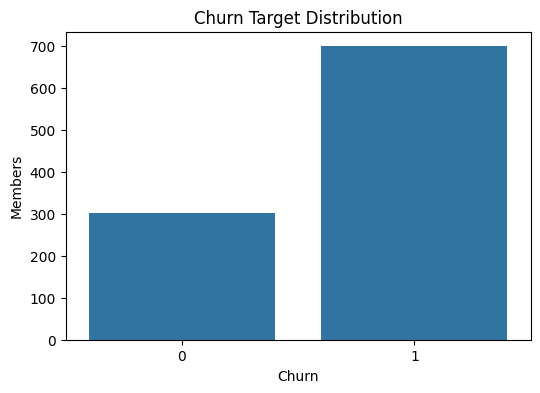

In [17]:
# 13. Target distribution

display(y.value_counts().rename(index={0: "Not churned", 1: "Churned"}).to_frame("count"))

plt.figure(figsize=(6,4))
sns.countplot(x=y)
plt.title("Churn Target Distribution")
plt.xlabel("Churn")
plt.ylabel("Members")
plt.show()


In [18]:
# 13.1 Missingness

missing = (
    X.isna().mean()
    .sort_values(ascending=False)
    .mul(100)
    .rename("missing_pct")
)

display(missing[missing > 0].to_frame())


,missing_pct
payment_count,14.4
total_paid,14.4
avg_payment,14.4
days_since_last_payment,14.4
membership_age_days,6.2
days_to_membership_end,6.2
attendance_count,5.8
attendance_last_30d,5.8
days_since_last_attendance,5.8


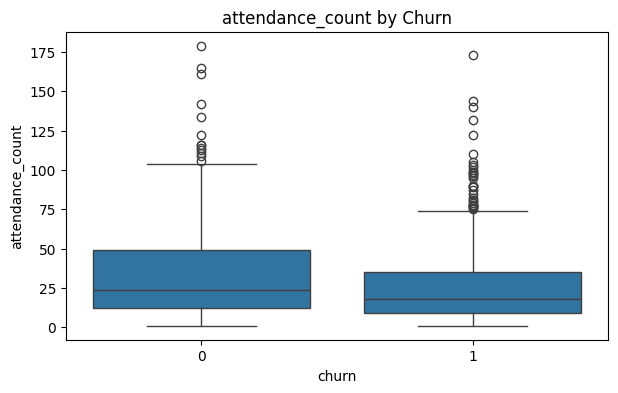

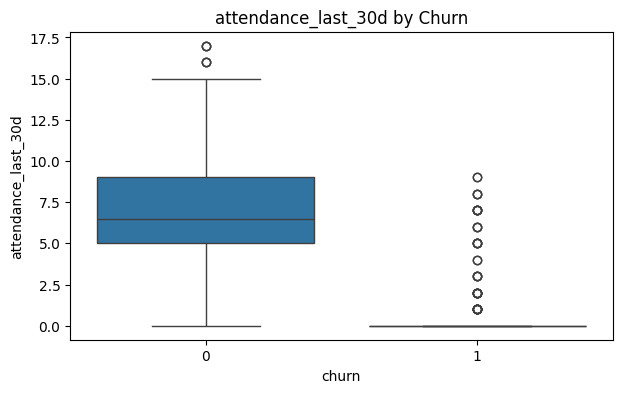

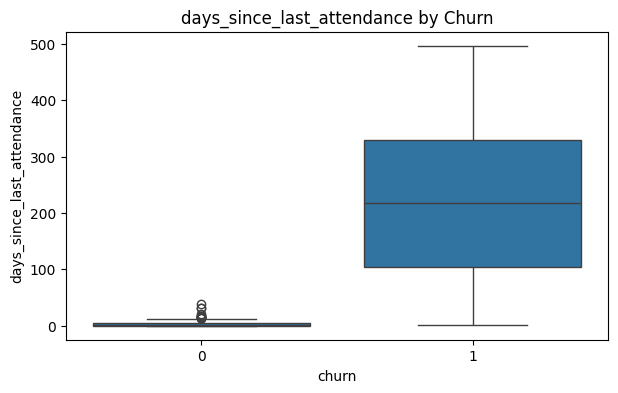

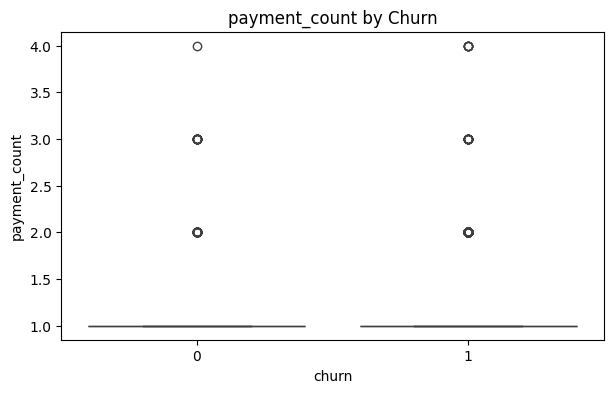

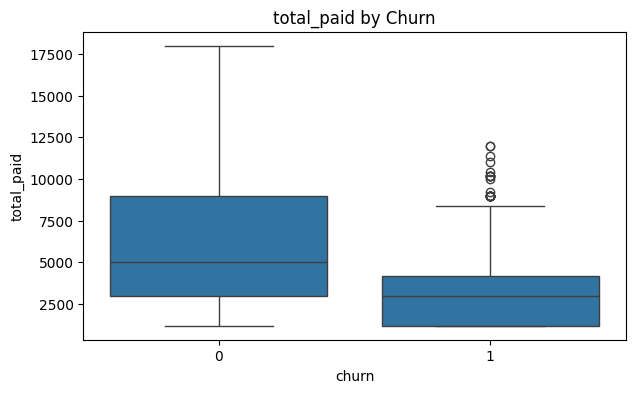

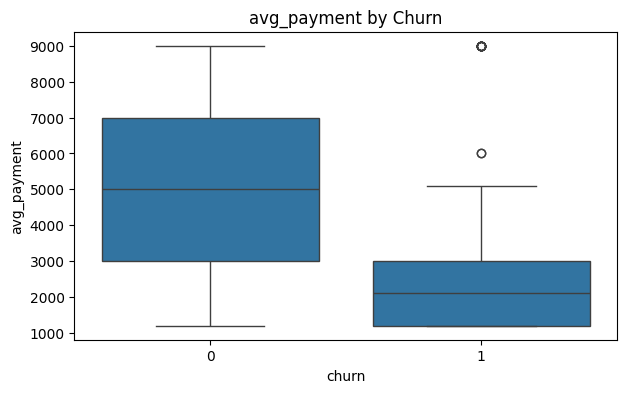

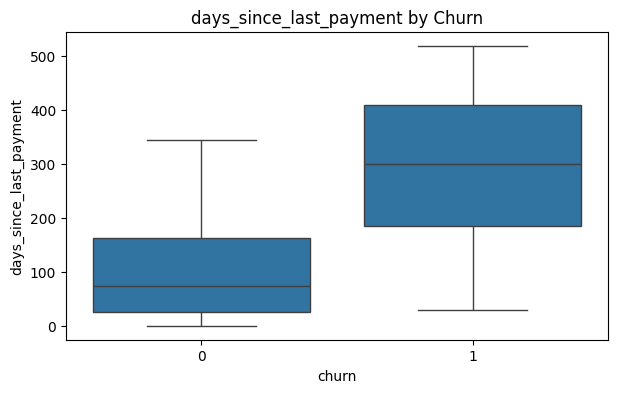

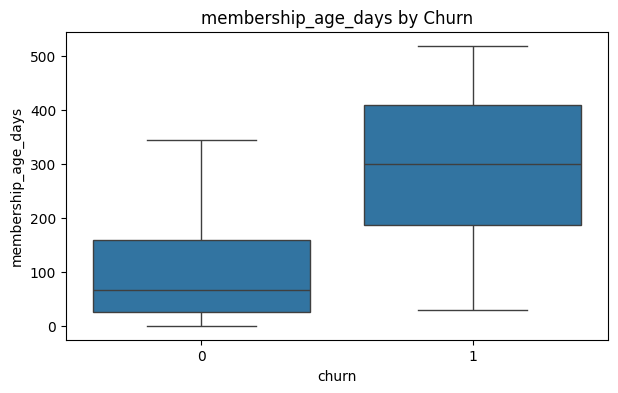

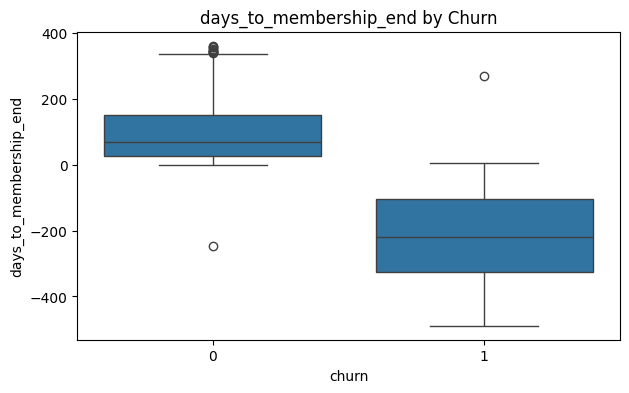

In [19]:
# 13.2 Numeric feature distributions by churn

numeric_cols = X.select_dtypes(include=np.number).columns.tolist()

for col in numeric_cols[:12]:
    plt.figure(figsize=(7,4))
    sns.boxplot(data=pd.concat([X[[col]], y.rename("churn")], axis=1),
                x="churn", y=col)
    plt.title(f"{col} by Churn")
    plt.show()


# 14. Train/test split

Use a stratified split so the class proportions are approximately preserved.

For a production-grade time-dependent model, a **temporal validation strategy** is preferable when multiple historical prediction cutoffs are available. This first notebook uses a transparent baseline split and documents that limitation.


In [20]:
# 14. Train/test split

X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X,
    y,
    prediction_ids,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)

print("Train:", X_train.shape)
print("Test :", X_test.shape)

print("\nTrain target rate:", y_train.mean().round(4))
print("Test target rate :", y_test.mean().round(4))


Train: (800, 11)
Test : (200, 11)

Train target rate: 0.6975
Test target rate : 0.7


# 15. Preprocessing pipeline

Numeric features:

- median imputation
- standardization

Categorical features:

- most-frequent imputation
- one-hot encoding

Using a pipeline keeps preprocessing inside the training workflow and helps prevent leakage.


In [21]:
# 15. Preprocessing

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)


Numeric features: ['attendance_count', 'attendance_last_30d', 'days_since_last_attendance', 'payment_count', 'total_paid', 'avg_payment', 'days_since_last_payment', 'membership_age_days', 'days_to_membership_end']
Categorical features: ['acquisition_source', 'gender']


# 16. Baseline model

Start with a simple dummy classifier and logistic regression.

This establishes whether the more complex models actually provide useful signal.


In [22]:
# 16. Baseline: dummy classifier

dummy = Pipeline([
    ("prep", preprocessor),
    ("model", DummyClassifier(strategy="prior", random_state=RANDOM_STATE))
])

dummy.fit(X_train, y_train)
dummy_prob = dummy.predict_proba(X_test)[:, 1]

print("Dummy ROC-AUC:", round(roc_auc_score(y_test, dummy_prob), 4))
print("Dummy PR-AUC :", round(average_precision_score(y_test, dummy_prob), 4))


Dummy ROC-AUC: 0.5
Dummy PR-AUC : 0.7


In [23]:
# 16.1 Logistic Regression baseline

logreg = Pipeline([
    ("prep", preprocessor),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

logreg.fit(X_train, y_train)
logreg_prob = logreg.predict_proba(X_test)[:, 1]
logreg_pred = (logreg_prob >= 0.50).astype(int)

print("Logistic ROC-AUC:", round(roc_auc_score(y_test, logreg_prob), 4))
print("Logistic PR-AUC :", round(average_precision_score(y_test, logreg_prob), 4))
print("\nClassification report:")
print(classification_report(y_test, logreg_pred, digits=4))


Logistic ROC-AUC: 0.9595
Logistic PR-AUC : 0.9825

Classification report:
              precision    recall  f1-score   support

           0     0.8500    0.8500    0.8500        60
           1     0.9357    0.9357    0.9357       140

    accuracy                         0.9100       200
   macro avg     0.8929    0.8929    0.8929       200
weighted avg     0.9100    0.9100    0.9100       200



# 17. Tree-based models

Random Forest is a strong, interpretable starting point for mixed business features.

A gradient boosting model is included as another comparison point.

The goal is **not** to pick the fanciest model. The goal is to compare performance, calibration, stability and business usefulness.


In [24]:
# 17. Random Forest

rf = Pipeline([
    ("prep", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=500,
        max_depth=None,
        min_samples_leaf=3,
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

rf.fit(X_train, y_train)
rf_prob = rf.predict_proba(X_test)[:, 1]
rf_pred = (rf_prob >= 0.50).astype(int)

print("Random Forest ROC-AUC:", round(roc_auc_score(y_test, rf_prob), 4))
print("Random Forest PR-AUC :", round(average_precision_score(y_test, rf_prob), 4))
print("\nClassification report:")
print(classification_report(y_test, rf_pred, digits=4))


Random Forest ROC-AUC: 1.0
Random Forest PR-AUC : 1.0

Classification report:
              precision    recall  f1-score   support

           0     0.9836    1.0000    0.9917        60
           1     1.0000    0.9929    0.9964       140

    accuracy                         0.9950       200
   macro avg     0.9918    0.9964    0.9941       200
weighted avg     0.9951    0.9950    0.9950       200



In [25]:
# 17.1 HistGradientBoosting
# Note: this model requires numerical transformed data, so we explicitly transform first.

prep_for_gb = preprocessor.fit(X_train, y_train)

X_train_gb = prep_for_gb.transform(X_train)
X_test_gb = prep_for_gb.transform(X_test)

gb = HistGradientBoostingClassifier(
    max_iter=300,
    learning_rate=0.05,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    random_state=RANDOM_STATE,
)

gb.fit(X_train_gb.toarray() if hasattr(X_train_gb, "toarray") else X_train_gb, y_train)

gb_X_test = X_test_gb.toarray() if hasattr(X_test_gb, "toarray") else X_test_gb
gb_prob = gb.predict_proba(gb_X_test)[:, 1]
gb_pred = (gb_prob >= 0.50).astype(int)

print("Gradient Boosting ROC-AUC:", round(roc_auc_score(y_test, gb_prob), 4))
print("Gradient Boosting PR-AUC :", round(average_precision_score(y_test, gb_prob), 4))
print("\nClassification report:")
print(classification_report(y_test, gb_pred, digits=4))


Gradient Boosting ROC-AUC: 1.0
Gradient Boosting PR-AUC : 1.0

Classification report:
              precision    recall  f1-score   support

           0     0.9836    1.0000    0.9917        60
           1     1.0000    0.9929    0.9964       140

    accuracy                         0.9950       200
   macro avg     0.9918    0.9964    0.9941       200
weighted avg     0.9951    0.9950    0.9950       200



# 18. Model comparison

For churn, ROC-AUC alone is not enough, especially if the positive class is uncommon.

Review:

- ROC-AUC
- PR-AUC
- precision
- recall
- F1
- confusion matrix

There is no universally correct probability threshold. The threshold should eventually be chosen using the gym's intervention capacity and the relative cost of missed churn vs unnecessary outreach.


In [26]:
# 18. Compare models

results = []

model_outputs = {
    "Logistic Regression": (logreg_prob, logreg_pred),
    "Random Forest": (rf_prob, rf_pred),
    "Gradient Boosting": (gb_prob, gb_pred),
}

for name, (prob, pred) in model_outputs.items():
    results.append({
        "model": name,
        "roc_auc": roc_auc_score(y_test, prob),
        "pr_auc": average_precision_score(y_test, prob),
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
        "f1": f1_score(y_test, pred, zero_division=0),
    })

results_df = pd.DataFrame(results).sort_values("pr_auc", ascending=False)
display(results_df)


,model,roc_auc,pr_auc,accuracy,precision,recall,f1
1,Random Forest,1.000000,1.000000,0.995,1.000000,0.992857,0.996416
2,Gradient Boosting,1.000000,1.000000,0.995,1.000000,0.992857,0.996416
0,Logistic Regression,0.959524,0.982476,0.910,0.935714,0.935714,0.935714


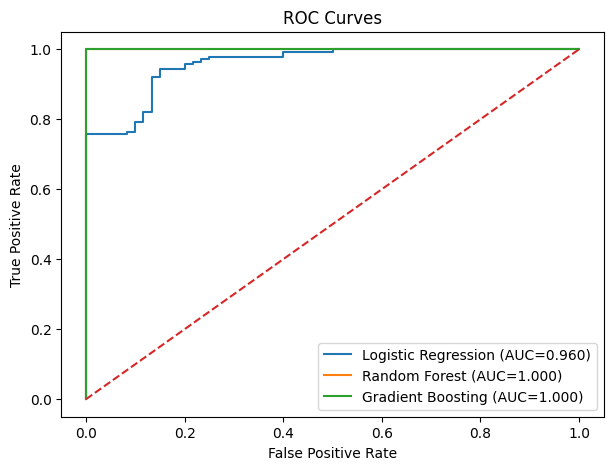

In [27]:
# 18.1 ROC curves

plt.figure(figsize=(7,5))

for name, (prob, _) in model_outputs.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")

plt.plot([0,1], [0,1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend()
plt.show()


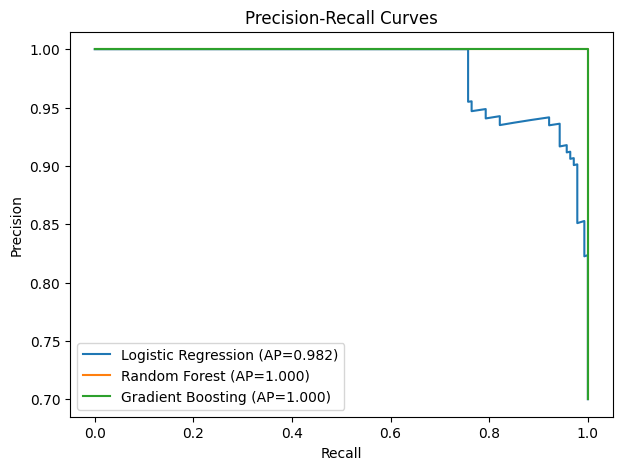

In [28]:
# 18.2 Precision-recall curves

plt.figure(figsize=(7,5))

for name, (prob, _) in model_outputs.items():
    precision, recall, _ = precision_recall_curve(y_test, prob)
    ap = average_precision_score(y_test, prob)
    plt.plot(recall, precision, label=f"{name} (AP={ap:.3f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves")
plt.legend()
plt.show()


# 19. Threshold analysis

For a gym, the useful question may be:

> "If staff can contact only the top N risky members each week, how many actual churners are captured?"

This is a business-oriented evaluation rather than blindly using 0.50.


In [29]:
# 19. Threshold table for the selected candidate model

# Start with Random Forest for illustration.
# This is NOT an automatic declaration that it is the final production model.
candidate_name = "Random Forest"
candidate_prob = rf_prob

threshold_rows = []

for threshold in np.arange(0.10, 0.91, 0.05):
    pred = (candidate_prob >= threshold).astype(int)
    threshold_rows.append({
        "threshold": round(float(threshold), 2),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
        "f1": f1_score(y_test, pred, zero_division=0),
        "flagged_members": int(pred.sum()),
    })

threshold_df = pd.DataFrame(threshold_rows)
display(threshold_df)


,threshold,precision,recall,f1,flagged_members
0,0.10,0.965517,1.000000,0.982456,145
1,0.15,1.000000,1.000000,1.000000,140
2,0.20,1.000000,1.000000,1.000000,140
3,0.25,1.000000,0.992857,0.996416,139
4,0.30,1.000000,0.992857,0.996416,139
5,0.35,1.000000,0.992857,0.996416,139
6,0.40,1.000000,0.992857,0.996416,139
7,0.45,1.000000,0.992857,0.996416,139
8,0.50,1.000000,0.992857,0.996416,139
9,0.55,1.000000,0.992857,0.996416,139


# 20. Confusion matrix

Review false positives and false negatives in business terms.

- False positive: member flagged as risky but does not churn.
- False negative: member not flagged but later churns.

The preferred balance depends on the gym's outreach capacity and intervention cost.


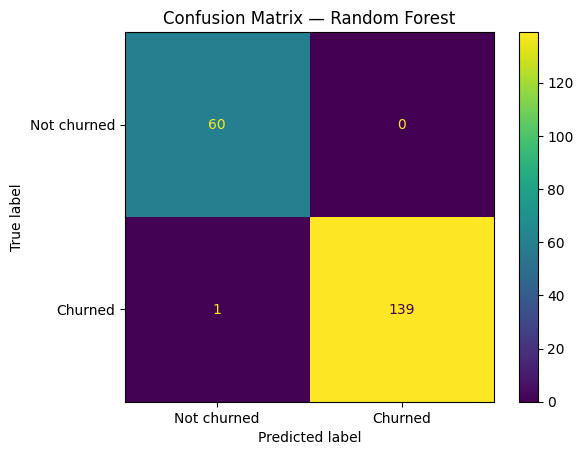

In [30]:
# 20. Confusion matrix

candidate_pred = (candidate_prob >= 0.50).astype(int)

cm = confusion_matrix(y_test, candidate_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not churned", "Churned"]
)
disp.plot()
plt.title(f"Confusion Matrix — {candidate_name}")
plt.show()


# 21. Cross-validation

A single train/test split can be noisy. Cross-validation gives a better view of model stability.

For the final production version, consider temporal cross-validation using multiple historical prediction cutoffs.


In [31]:
# 21. Stratified cross-validation for logistic regression and RF

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

scoring = {
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
    "f1": "f1",
    "recall": "recall",
    "precision": "precision",
}

cv_models = {
    "Logistic Regression": logreg,
    "Random Forest": rf,
}

cv_rows = []

for name, model in cv_models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
    )

    cv_rows.append({
        "model": name,
        "roc_auc_mean": scores["test_roc_auc"].mean(),
        "roc_auc_std": scores["test_roc_auc"].std(),
        "pr_auc_mean": scores["test_average_precision"].mean(),
        "pr_auc_std": scores["test_average_precision"].std(),
        "f1_mean": scores["test_f1"].mean(),
        "recall_mean": scores["test_recall"].mean(),
        "precision_mean": scores["test_precision"].mean(),
    })

cv_results = pd.DataFrame(cv_rows)
display(cv_results)


,model,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,f1_mean,recall_mean,precision_mean
0,Logistic Regression,0.955382,0.014864,0.977923,0.009618,0.927581,0.922876,0.933108
1,Random Forest,0.996472,0.003443,0.998617,0.001277,0.985584,0.980325,0.991131


# 22. Feature importance / interpretation

For the Random Forest pipeline, extract feature names after preprocessing and inspect which variables contribute most to the model.

Treat feature importance as an explanation aid, not as proof that a feature causally causes churn.


In [32]:
# 22. Random Forest feature importance

rf_prep = rf.named_steps["prep"]
rf_model = rf.named_steps["model"]

feature_names = rf_prep.get_feature_names_out()

importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": rf_model.feature_importances_,
}).sort_values("importance", ascending=False)

display(importance_df.head(25))


,feature,importance
8,num__days_to_membership_end,0.315989
2,num__days_since_last_attendance,0.244575
1,num__attendance_last_30d,0.148110
7,num__membership_age_days,0.114873
6,num__days_since_last_payment,0.077538
0,num__attendance_count,0.041182
5,num__avg_payment,0.028291
4,num__total_paid,0.020213
3,num__payment_count,0.002439
9,cat__acquisition_source_Google,0.001380


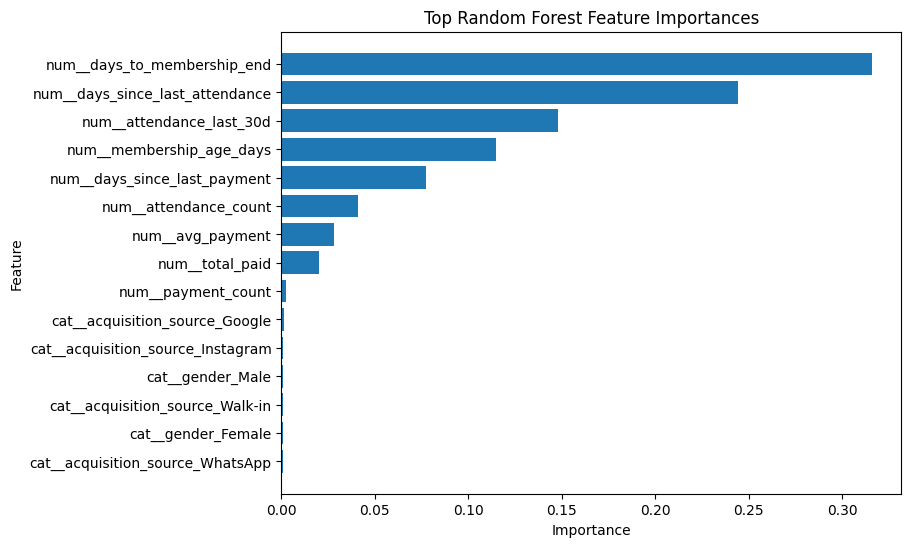

In [33]:
# 22.1 Plot top feature importances

top_n = 15
plot_df = importance_df.head(top_n).sort_values("importance")

plt.figure(figsize=(8,6))
plt.barh(plot_df["feature"], plot_df["importance"])
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top Random Forest Feature Importances")
plt.show()


In [36]:

# FITCORE - Churn Feature Leakage Investigation

# 1. Compare membership expiry against actual churn

audit_df = model_df.copy()

print("MEMBERSHIP EXPIRY ANALYSIS")
print("=" * 50)

expiry_col = "days_to_membership_end"

if expiry_col in audit_df.columns:

    display(
        audit_df.groupby("churn")[expiry_col]
        .agg(["count", "mean", "median", "min", "max"])
        .round(2)
    )

    # Check whether membership expires within the
    # next 30 days from the observation cutoff.

    audit_df["expires_within_30d"] = (
        audit_df[expiry_col].between(0, 30)
    )

    print("\nChurn rate by expiry window:")

    display(
        audit_df.groupby("expires_within_30d")["churn"]
        .agg(["count", "mean"])
        .rename(columns={"mean": "churn_rate"})
    )

else:
    print("Membership expiry feature not found.")


# 2. Attendance behaviour against churn

print("\nATTENDANCE ANALYSIS")
print("=" * 50)

attendance_cols = [
    "days_since_last_attendance",
    "attendance_last_30d",
    "attendance_count"
]

available = [
    c for c in attendance_cols
    if c in audit_df.columns
]

display(
    audit_df.groupby("churn")[available]
    .agg(["mean", "median"])
    .round(2)
)


# 3. Check missing feature values

print("\nMISSING FEATURE VALUES")
print("=" * 50)

display(
    audit_df.isnull().sum()
    .sort_values(ascending=False)
    .to_frame("missing_count")
)


MEMBERSHIP EXPIRY ANALYSIS


,count,mean,median,min,max
churn,,,,,
0,258,97.85,68.5,-247.0,361.0
1,680,-218.11,-218.5,-489.0,269.0



Churn rate by expiry window:


,count,churn_rate
expires_within_30d,,
False,915,0.757377
True,85,0.058824



ATTENDANCE ANALYSIS


days_since_last_attendance        attendance_last_30d         \
                            mean median                mean median   
churn                                                                
0                           3.61    2.0                7.17    6.5   
1                         221.34  218.0                0.25    0.0   

      attendance_count         
                  mean median  
churn                          
0                34.94   24.0  
1                25.78   18.0


MISSING FEATURE VALUES


,missing_count
payment_count,144
total_paid,144
avg_payment,144
days_since_last_payment,144
days_to_membership_end,62
membership_age_days,62
attendance_count,58
first_attendance,58
last_attendance,58
attendance_last_30d,58


# 23. Generate member-level risk predictions

This creates a practical output table containing:

- member ID
- predicted churn probability
- risk band

**Risk bands are operational labels, not a claim that a member will definitely churn.**


In [34]:
# 23. Generate test-set risk output

risk_output = pd.DataFrame({
    MEMBER_ID_COL: id_test.values,
    "actual_churn": y_test.values,
    "churn_probability": candidate_prob,
})

risk_output["risk_band"] = pd.cut(
    risk_output["churn_probability"],
    bins=[-np.inf, 0.30, 0.60, np.inf],
    labels=["Lower", "Medium", "Higher"]
)

risk_output = risk_output.sort_values(
    "churn_probability",
    ascending=False
)

display(risk_output.head(20))


,member_id,actual_churn,churn_probability,risk_band
199,MEM0949,1,1.0,Higher
48,MEM0172,1,1.0,Higher
140,MEM0542,1,1.0,Higher
131,MEM0641,1,1.0,Higher
127,MEM0323,1,1.0,Higher
38,MEM0237,1,1.0,Higher
125,MEM0465,1,1.0,Higher
115,MEM0054,1,1.0,Higher
45,MEM0031,1,1.0,Higher
114,MEM0501,1,1.0,Higher


# 24. Business-facing output

The final system should not expose raw model internals to gym staff.

A practical dashboard view could show:

- member
- churn risk
- recent attendance
- membership status/end date
- recent payment activity
- recommended follow-up status

The recommendation/action layer should be implemented only after validating the model.


In [37]:

# FITCORE: Active Membership Eligibility Audit

ms = dfs["memberships"].copy()

ms_id = find_col(
    ms, ["member_id", "memberid"]
)

start_col = find_col(
    ms, ["start_date_dt", "start_date"]
)

end_col = find_col(
    ms, ["end_date_dt", "end_date", "expiry_date"]
)

if not all([ms_id, start_col, end_col]):
    raise ValueError(
        "Could not identify membership ID/start/end columns."
    )

ms["_start"] = pd.to_datetime(
    ms[start_col], errors="coerce"
)

ms["_end"] = pd.to_datetime(
    ms[end_col], errors="coerce"
)

# Membership active on observation cutoff
active_ms = ms[
    (ms["_start"] <= OBSERVATION_CUTOFF) &
    (ms["_end"] >= OBSERVATION_CUTOFF)
].copy()

active_member_ids = (
    active_ms[ms_id]
    .astype("string")
    .str.strip()
    .dropna()
    .unique()
)

# Match eligible members with churn outcomes
audit = model_df.copy()

audit["_id"] = (
    audit[MEMBER_ID_COL]
    .astype("string")
    .str.strip()
)

audit["active_at_cutoff"] = (
    audit["_id"].isin(active_member_ids)
)

print("TOTAL MEMBERS:", len(audit))

print("\nACTIVE MEMBERSHIP STATUS:")
print(audit["active_at_cutoff"].value_counts())

print("\nCHURN DISTRIBUTION BY MEMBERSHIP STATUS:")

display(
    audit.groupby("active_at_cutoff")["churn"]
    .agg(
        member_count="count",
        churned="sum",
        churn_rate="mean"
    )
)

print("\nACTIVE MEMBERS ONLY:")
active_audit = audit[
    audit["active_at_cutoff"]
]

display(
    active_audit["churn"]
    .value_counts()
    .rename("member_count")
)

print(
    "\nActive-membership churn rate:",
    round(active_audit["churn"].mean(), 4)
    if len(active_audit) else "No eligible members"
)


TOTAL MEMBERS: 1000

ACTIVE MEMBERSHIP STATUS:
active_at_cutoff
False    737
True     263
Name: count, dtype: int64

CHURN DISTRIBUTION BY MEMBERSHIP STATUS:


,member_count,churned,churn_rate
active_at_cutoff,,,
False,737,692,0.938942
True,263,6,0.022814



ACTIVE MEMBERS ONLY:


churn
0    257
1      6
Name: member_count, dtype: int64


Active-membership churn rate: 0.0228


In [38]:

# FITCORE - Historical Membership Coverage Audit

ms = dfs["memberships"].copy()

start_col = find_col(
    ms, ["start_date_dt", "start_date"]
)

end_col = find_col(
    ms, ["end_date_dt", "end_date", "expiry_date"]
)

ms["_start"] = pd.to_datetime(
    ms[start_col], errors="coerce"
)

ms["_end"] = pd.to_datetime(
    ms[end_col], errors="coerce"
)

print("MEMBERSHIP RECORDS")
print("=" * 45)

print("Total records:", len(ms))
print("Unique members:", ms[MEMBER_ID_COL].nunique())
print("Missing start dates:", ms["_start"].isna().sum())
print("Missing end dates:", ms["_end"].isna().sum())

print("\nSTART DATE RANGE")
print(ms["_start"].min(), "to", ms["_start"].max())

print("\nEND DATE RANGE")
print(ms["_end"].min(), "to", ms["_end"].max())

print("\nMEMBERSHIP RECORDS BY YEAR")

display(
    ms.assign(
        start_year=ms["_start"].dt.year
    )
    .groupby("start_year")
    .size()
    .rename("membership_records")
    .to_frame()
)

print("\nMEMBERSHIPS PER MEMBER")

display(
    ms.groupby(MEMBER_ID_COL)
    .size()
    .value_counts()
    .sort_index()
    .rename_axis("membership_records_per_member")
    .to_frame("number_of_members")
)


MEMBERSHIP RECORDS
Total records: 1300
Unique members: 984
Missing start dates: 0
Missing end dates: 0

START DATE RANGE
2025-03-16 00:00:00 to 2026-09-16 00:00:00

END DATE RANGE
2025-04-15 00:00:00 to 2027-09-15 00:00:00

MEMBERSHIP RECORDS BY YEAR


,membership_records
start_year,
2025,677
2026,623



MEMBERSHIPS PER MEMBER


,number_of_members
membership_records_per_member,
1,734
2,194
3,46
4,10


In [40]:

# FITCORE - Membership Overlap Audit

ms = dfs["memberships"].copy()

ms["_start"] = pd.to_datetime(
    ms["start_date_dt"], errors="coerce"
)

ms["_end"] = pd.to_datetime(
    ms["end_date_dt"], errors="coerce"
)

# Sort membership records chronologically
ms = ms.sort_values(
    [MEMBER_ID_COL, "_start"]
).copy()

# Maximum end date among previous records for each member
ms["_previous_max_end"] = (
    ms.groupby(MEMBER_ID_COL)["_end"]
    .transform(lambda s: s.cummax().shift())
)

# Check whether a new membership starts before
# the previous membership period has ended.
ms["overlap"] = (
    ms["_start"] <= ms["_previous_max_end"]
)

print("TOTAL MEMBERSHIP RECORDS:", len(ms))

print(
    "OVERLAPPING RECORDS:",
    int(ms["overlap"].sum())
)

print(
    "MEMBERS WITH OVERLAPPING RECORDS:",
    ms.loc[ms["overlap"], MEMBER_ID_COL].nunique()
)

print("\nOVERLAP EXAMPLES:")

display(
    ms.loc[
        ms["overlap"],
        [
            MEMBER_ID_COL,
            "_start",
            "_end",
            "_previous_max_end"
        ]
    ].head(20)
)


TOTAL MEMBERSHIP RECORDS: 1300
OVERLAPPING RECORDS: 0
MEMBERS WITH OVERLAPPING RECORDS: 0

OVERLAP EXAMPLES:


,member_id,_start,_end,_previous_max_end


In [41]:

# FITCORE - HISTORICAL MEMBER SNAPSHOT DATASET

import pandas as pd
import numpy as np

# --------------------------------------------------
# 1. PREPARE SOURCE TABLES
# --------------------------------------------------

members = dfs["members"].copy()
memberships = dfs["memberships"].copy()
attendance = dfs["attendance"].copy()
payments = dfs["payments"].copy()

# Identify columns
member_id = MEMBER_ID_COL

ms_id = find_col(memberships, ["member_id", "memberid"])
ms_start = find_col(memberships, ["start_date", "start_date_dt"])
ms_end = find_col(memberships, ["end_date", "end_date_dt"])

att_id = find_col(attendance, ["member_id", "memberid"])
att_date = find_col(
    attendance,
    ["check_in_date", "check_in_date_dt", "attendance_date"]
)

pay_id = find_col(payments, ["member_id", "memberid"])
pay_date = find_col(
    payments,
    ["payment_date", "payment_date_dt", "paid_date"]
)
pay_amount = find_col(
    payments,
    ["amount", "payment_amount", "paid_amount", "total_amount"]
)

required = {
    "membership ID": ms_id,
    "membership start": ms_start,
    "membership end": ms_end,
    "attendance ID": att_id,
    "attendance date": att_date
}

missing = [name for name, col in required.items() if col is None]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

# Normalize dates and IDs
members["_id"] = members[member_id].astype("string").str.strip()

memberships["_id"] = memberships[ms_id].astype("string").str.strip()
memberships["_start"] = pd.to_datetime(memberships[ms_start], errors="coerce")
memberships["_end"] = pd.to_datetime(memberships[ms_end], errors="coerce")

attendance["_id"] = attendance[att_id].astype("string").str.strip()
attendance["_date"] = pd.to_datetime(attendance[att_date], errors="coerce")

payments["_id"] = payments[pay_id].astype("string").str.strip()
payments["_date"] = pd.to_datetime(payments[pay_date], errors="coerce")

if pay_amount:
    payments["_amount"] = pd.to_numeric(
        payments[pay_amount], errors="coerce"
    )

# Remove invalid records
memberships = memberships.dropna(subset=["_id", "_start", "_end"])
attendance = attendance.dropna(subset=["_id", "_date"])
payments = payments.dropna(subset=["_id", "_date"])

# --------------------------------------------------
# 2. DEFINE SNAPSHOT DATES
# --------------------------------------------------

snapshot_dates = []

current = pd.Timestamp("2025-04-16")
last_snapshot = pd.Timestamp("2026-08-16")

while current <= last_snapshot:
    snapshot_dates.append(current)
    current = current + pd.DateOffset(months=1)

print("Number of snapshot dates:", len(snapshot_dates))
print("First snapshot:", snapshot_dates[0])
print("Last snapshot:", snapshot_dates[-1])

# --------------------------------------------------
# 3. BUILD MEMBER SNAPSHOTS
# --------------------------------------------------

snapshot_rows = []

for snapshot in snapshot_dates:

    history_start = snapshot - pd.Timedelta(days=30)
    history_90d = snapshot - pd.Timedelta(days=90)
    future_end = snapshot + pd.Timedelta(days=30)

    # Membership active at snapshot
    active_memberships = memberships[
        (memberships["_start"] <= snapshot) &
        (memberships["_end"] >= snapshot)
    ]

    active_ids = set(active_memberships["_id"])

    # Attendance history and future attendance
    hist_att = attendance[
        (attendance["_date"] > history_start) &
        (attendance["_date"] <= snapshot)
    ]

    future_att = attendance[
        (attendance["_date"] > snapshot) &
        (attendance["_date"] <= future_end)
    ]

    hist_90 = attendance[
        (attendance["_date"] > history_90d) &
        (attendance["_date"] <= snapshot)
    ]

    # Recently engaged members only
    recent_ids = set(hist_att["_id"])

    eligible_ids = active_ids.intersection(recent_ids)

    # Build one observation per eligible member
    for mid in eligible_ids:

        member_att = hist_att[hist_att["_id"] == mid]
        member_att_90 = hist_90[hist_90["_id"] == mid]
        member_future = future_att[future_att["_id"] == mid]

        # Membership active records for this member
        member_ms = active_memberships[
            active_memberships["_id"] == mid
        ]

        latest_membership = member_ms.sort_values("_start").iloc[-1]

        row = {
            "member_id": mid,
            "snapshot_date": snapshot,

            "attendance_last_30d": len(member_att),
            "attendance_last_90d": len(member_att_90),

            "days_since_last_attendance": (
                snapshot - member_att["_date"].max()
            ).days,

            "membership_age_days": (
                snapshot - latest_membership["_start"]
            ).days,

            "days_to_membership_end": (
                latest_membership["_end"] - snapshot
            ).days,

            "future_attendance_count": len(member_future),

            "inactivity_30d": int(len(member_future) == 0)
        }

        # Payment features using information available by snapshot
        member_pay = payments[
            (payments["_id"] == mid) &
            (payments["_date"] <= snapshot)
        ]

        row["payment_count"] = len(member_pay)

        if pay_amount:
            row["total_paid"] = member_pay["_amount"].sum()
            row["avg_payment"] = member_pay["_amount"].mean()

        if len(member_pay):
            row["days_since_last_payment"] = (
                snapshot - member_pay["_date"].max()
            ).days
        else:
            row["days_since_last_payment"] = np.nan

        snapshot_rows.append(row)

# --------------------------------------------------
# 4. CREATE FINAL DATASET
# --------------------------------------------------

snapshot_df = pd.DataFrame(snapshot_rows)

if snapshot_df.empty:
    raise ValueError("No eligible historical snapshots were generated.")

snapshot_df = snapshot_df.sort_values(
    ["snapshot_date", "member_id"]
).reset_index(drop=True)

# --------------------------------------------------
# 5. VALIDATE DATASET
# --------------------------------------------------

print("\n" + "=" * 55)
print("FITCORE HISTORICAL SNAPSHOT DATASET")
print("=" * 55)

print("Total observations:", len(snapshot_df))
print("Unique members:", snapshot_df["member_id"].nunique())
print("Snapshot dates:", snapshot_df["snapshot_date"].nunique())

print("\nTarget distribution:")
print(snapshot_df["inactivity_30d"].value_counts())

print("\nTarget rate:")
print(snapshot_df["inactivity_30d"].mean().round(4))

print("\nObservations per member:")
display(
    snapshot_df.groupby("member_id")
    .size()
    .describe()
    .to_frame("snapshot_count")
)

print("\nMissing values:")
display(
    snapshot_df.isna().sum().to_frame("missing_count")
)

print("\nSample observations:")
display(snapshot_df.head(10))

# Save the historical dataset
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

snapshot_path = OUTPUT_DIR / "fitcore_historical_snapshots.csv"

snapshot_df.to_csv(snapshot_path, index=False)

print("\nSaved:", snapshot_path)


Number of snapshot dates: 17
First snapshot: 2025-04-16 00:00:00
Last snapshot: 2026-08-16 00:00:00

FITCORE HISTORICAL SNAPSHOT DATASET
Total observations: 3327
Unique members: 906
Snapshot dates: 17

Target distribution:
inactivity_30d
0    3212
1     115
Name: count, dtype: int64

Target rate:
0.0346

Observations per member:


,snapshot_count
count,906.000000
mean,3.672185
std,3.039271
min,1.000000
25%,1.000000
50%,3.000000
75%,5.000000
max,16.000000



Missing values:


,missing_count
member_id,0
snapshot_date,0
attendance_last_30d,0
attendance_last_90d,0
days_since_last_attendance,0
membership_age_days,0
days_to_membership_end,0
future_attendance_count,0
inactivity_30d,0
payment_count,0



Sample observations:


,member_id,snapshot_date,attendance_last_30d,attendance_last_90d,days_since_last_attendance,membership_age_days,days_to_membership_end,future_attendance_count,inactivity_30d,payment_count,total_paid,avg_payment,days_since_last_payment
0,MEM0015,2025-04-16,13,14,3,30,60,11,0,1,3000.0,3000.0,30.0
1,MEM0051,2025-04-16,4,4,0,17,163,4,0,0,0.0,NaN,NaN
2,MEM0063,2025-04-16,2,2,2,17,73,3,0,1,3000.0,3000.0,17.0
3,MEM0073,2025-04-16,4,4,3,25,155,9,0,1,5000.0,5000.0,25.0
4,MEM0076,2025-04-16,1,1,2,3,177,18,0,1,5000.0,5000.0,3.0
5,MEM0082,2025-04-16,3,3,4,15,15,2,0,1,1200.0,1200.0,15.0
6,MEM0087,2025-04-16,1,1,2,3,27,6,0,1,1200.0,1200.0,3.0
7,MEM0139,2025-04-16,2,2,6,7,83,6,0,1,3000.0,3000.0,7.0
8,MEM0145,2025-04-16,4,4,3,11,169,3,0,1,5000.0,5000.0,11.0
9,MEM0156,2025-04-16,2,2,11,18,72,5,0,0,0.0,NaN,NaN



Saved: D:\ML Projects\Gym Business Intelligence System\notebooks\ml_outputs\fitcore_historical_snapshots.csv


In [42]:

# FITCORE - Historical Snapshot Quality Audit

# 1. Verify unique member-snapshot combinations

print("DUPLICATE SNAPSHOTS")

print(
    "Duplicate member-date rows:",
    snapshot_df.duplicated(
        subset=["member_id", "snapshot_date"]
    ).sum()
)

# 2. Target distribution by snapshot

print("\nINACTIVITY RATE BY SNAPSHOT")

display(
    snapshot_df.groupby("snapshot_date")
    .agg(
        observations=("member_id", "count"),
        inactive=("inactivity_30d", "sum"),
        inactivity_rate=("inactivity_30d", "mean")
    )
    .round(4)
)

# 3. Number of distinct members with at least one
# positive inactivity observation

positive_members = (
    snapshot_df.loc[
        snapshot_df["inactivity_30d"] == 1,
        "member_id"
    ].nunique()
)

print("\nUNIQUE MEMBERS WITH INACTIVITY EVENTS:", positive_members)

# 4. Check future outcome consistency

print("\nTARGET CONSISTENCY")

print(
    "Incorrect labels:",
    (
        snapshot_df["inactivity_30d"] !=
        (snapshot_df["future_attendance_count"] == 0).astype(int)
    ).sum()
)

# 5. Snapshot date coverage

print("\nSNAPSHOT COVERAGE")

print("First:", snapshot_df["snapshot_date"].min())
print("Last:", snapshot_df["snapshot_date"].max())

# 6. Verify feature availability

print("\nFEATURE COLUMNS")

excluded = [
    "member_id",
    "snapshot_date",
    "future_attendance_count",
    "inactivity_30d"
]

candidate_features = [
    c for c in snapshot_df.columns
    if c not in excluded
]

print("Predictor candidates:")
print(candidate_features)

print("\nPositive observations by member:")
display(
    snapshot_df.loc[
        snapshot_df["inactivity_30d"] == 1
    ]
    .groupby("member_id")
    .size()
    .value_counts()
    .sort_index()
    .to_frame("number_of_members")
)


DUPLICATE SNAPSHOTS
Duplicate member-date rows: 0

INACTIVITY RATE BY SNAPSHOT


,observations,inactive,inactivity_rate
snapshot_date,,,
2025-04-16,54,2,0.0370
2025-05-16,97,4,0.0412
2025-06-16,145,8,0.0552
2025-07-16,168,10,0.0595
2025-08-16,176,6,0.0341
2025-09-16,184,5,0.0272
2025-10-16,192,10,0.0521
2025-11-16,210,7,0.0333
2025-12-16,199,7,0.0352



UNIQUE MEMBERS WITH INACTIVITY EVENTS: 115

TARGET CONSISTENCY
Incorrect labels: 0

SNAPSHOT COVERAGE
First: 2025-04-16 00:00:00
Last: 2026-08-16 00:00:00

FEATURE COLUMNS
Predictor candidates:
['attendance_last_30d', 'attendance_last_90d', 'days_since_last_attendance', 'membership_age_days', 'days_to_membership_end', 'payment_count', 'total_paid', 'avg_payment', 'days_since_last_payment']

Positive observations by member:


,number_of_members
1,115


In [43]:

# FITCORE - Chronological ML Dataset Split

import pandas as pd
import numpy as np

# 1. Prepare dataset
ml_data = snapshot_df.copy()

ml_data["snapshot_date"] = pd.to_datetime(
    ml_data["snapshot_date"]
)

ml_data = ml_data.sort_values(
    "snapshot_date"
).reset_index(drop=True)

# 2. Define chronological boundaries
TRAIN_END = pd.Timestamp("2026-03-16")
VALIDATION_END = pd.Timestamp("2026-05-16")

# 3. Split by snapshot date
train_df = ml_data[
    ml_data["snapshot_date"] <= TRAIN_END
].copy()

validation_df = ml_data[
    (ml_data["snapshot_date"] > TRAIN_END) &
    (ml_data["snapshot_date"] <= VALIDATION_END)
].copy()

test_df = ml_data[
    ml_data["snapshot_date"] > VALIDATION_END
].copy()

# 4. Define target and predictors
TARGET = "inactivity_30d"

EXCLUDED_COLUMNS = [
    "member_id",
    "snapshot_date",
    "future_attendance_count",
    TARGET
]

FEATURES = [
    col for col in ml_data.columns
    if col not in EXCLUDED_COLUMNS
]

# Only use numeric predictors for this first baseline
FEATURES = [
    col for col in FEATURES
    if pd.api.types.is_numeric_dtype(ml_data[col])
]

# 5. Create X and y
X_train = train_df[FEATURES]
y_train = train_df[TARGET]

X_val = validation_df[FEATURES]
y_val = validation_df[TARGET]

X_test = test_df[FEATURES]
y_test = test_df[TARGET]

# 6. Validate split
print("=" * 55)
print("FITCORE CHRONOLOGICAL DATASET SPLIT")
print("=" * 55)

for name, df, y in [
    ("TRAIN", train_df, y_train),
    ("VALIDATION", validation_df, y_val),
    ("TEST", test_df, y_test)
]:

    print(f"\n{name}")
    print("Date range:", df["snapshot_date"].min(),
          "to", df["snapshot_date"].max())
    print("Observations:", len(df))
    print("Positive cases:", int(y.sum()))
    print("Negative cases:", int((y == 0).sum()))
    print("Inactivity rate:", round(y.mean(), 4))

print("\nFeatures:", FEATURES)

# 7. Leakage checks
assert "future_attendance_count" not in FEATURES
assert TARGET not in FEATURES
assert train_df["snapshot_date"].max() < validation_df["snapshot_date"].min()
assert validation_df["snapshot_date"].max() < test_df["snapshot_date"].min()

print("\nChronological split checks passed.")


FITCORE CHRONOLOGICAL DATASET SPLIT

TRAIN
Date range: 2025-04-16 00:00:00 to 2026-03-16 00:00:00
Observations: 2096
Positive cases: 78
Negative cases: 2018
Inactivity rate: 0.0372

VALIDATION
Date range: 2026-04-16 00:00:00 to 2026-05-16 00:00:00
Observations: 472
Positive cases: 15
Negative cases: 457
Inactivity rate: 0.0318

TEST
Date range: 2026-06-16 00:00:00 to 2026-08-16 00:00:00
Observations: 759
Positive cases: 22
Negative cases: 737
Inactivity rate: 0.029

Features: ['attendance_last_30d', 'attendance_last_90d', 'days_since_last_attendance', 'membership_age_days', 'days_to_membership_end', 'payment_count', 'total_paid', 'avg_payment', 'days_since_last_payment']

Chronological split checks passed.


In [44]:

# FITCORE - Revised Historical Inactivity Model Training

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# --------------------------------------------------
# 1. VALIDATE TRAINING DATA
# --------------------------------------------------

print("TRAINING DATA VALIDATION")

print("Training observations:", len(X_train))
print("Training positive cases:", int(y_train.sum()))

if y_train.nunique() < 2:
    raise ValueError("Training data must contain both target classes.")

if y_val.nunique() < 2:
    raise ValueError("Validation data must contain both target classes.")

if y_test.nunique() < 2:
    raise ValueError("Test data must contain both target classes.")

# --------------------------------------------------
# 2. RANDOM FOREST PIPELINE
# --------------------------------------------------

rf_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="median",
            add_indicator=True
        )
    ),
    (
        "model",
        RandomForestClassifier(
            n_estimators=500,
            max_depth=6,
            min_samples_split=10,
            min_samples_leaf=5,
            max_features="sqrt",
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=-1
        )
    )
])

# --------------------------------------------------
# 3. LOGISTIC REGRESSION PIPELINE
# --------------------------------------------------

lr_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="median",
            add_indicator=True
        )
    ),
    (
        "scaler",
        StandardScaler()
    ),
    (
        "model",
        LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        )
    )
])

# --------------------------------------------------
# 4. TRAIN USING TRAINING DATA ONLY
# --------------------------------------------------

print("\nTraining Random Forest...")

rf_pipeline.fit(X_train, y_train)

print("Random Forest trained.")

print("\nTraining Logistic Regression...")

lr_pipeline.fit(X_train, y_train)

print("Logistic Regression trained.")

# --------------------------------------------------
# 5. VALIDATION EVALUATION
# --------------------------------------------------

models = {
    "Random Forest": rf_pipeline,
    "Logistic Regression": lr_pipeline
}

validation_results = []
validation_predictions = {}

for name, model in models.items():

    probabilities = model.predict_proba(X_val)[:, 1]

    predictions = (probabilities >= 0.5).astype(int)

    validation_predictions[name] = probabilities

    validation_results.append({
        "model": name,
        "roc_auc": roc_auc_score(y_val, probabilities),
        "pr_auc": average_precision_score(y_val, probabilities),
        "precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "f1": f1_score(
            y_val, predictions, zero_division=0
        )
    })

validation_results_df = pd.DataFrame(
    validation_results
).sort_values("pr_auc", ascending=False)

print("\nVALIDATION MODEL COMPARISON")

display(validation_results_df.round(4))

# --------------------------------------------------
# 6. RANDOM FOREST VALIDATION DETAILS
# --------------------------------------------------

rf_val_prob = validation_predictions["Random Forest"]

rf_val_pred = (rf_val_prob >= 0.5).astype(int)

print("\nRANDOM FOREST VALIDATION CONFUSION MATRIX")

display(
    pd.DataFrame(
        confusion_matrix(y_val, rf_val_pred),
        index=["Actual 0", "Actual 1"],
        columns=["Predicted 0", "Predicted 1"]
    )
)

print("\nCLASSIFICATION REPORT")

print(
    classification_report(
        y_val,
        rf_val_pred,
        zero_division=0
    )
)

print("\nValidation positive cases:", int(y_val.sum()))

print(
    "Random Forest detected:",
    int(((y_val == 1) & (rf_val_pred == 1)).sum())
)

print(
    "Random Forest missed:",
    int(((y_val == 1) & (rf_val_pred == 0)).sum())
)

print("\nValidation complete.")
print("The final test set has NOT been used.")


TRAINING DATA VALIDATION
Training observations: 2096
Training positive cases: 78

Training Random Forest...
Random Forest trained.

Training Logistic Regression...
Logistic Regression trained.

VALIDATION MODEL COMPARISON


,model,roc_auc,pr_auc,precision,recall,f1
0,Random Forest,0.9113,0.3328,0.2571,0.6,0.3600
1,Logistic Regression,0.8818,0.2378,0.1250,0.8,0.2162



RANDOM FOREST VALIDATION CONFUSION MATRIX


,Predicted 0,Predicted 1
Actual 0,431,26
Actual 1,6,9



CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.99      0.94      0.96       457
           1       0.26      0.60      0.36        15

    accuracy                           0.93       472
   macro avg       0.62      0.77      0.66       472
weighted avg       0.96      0.93      0.95       472


Validation positive cases: 15
Random Forest detected: 9
Random Forest missed: 6

Validation complete.
The final test set has NOT been used.


In [45]:

# FITCORE - Random Forest Threshold Analysis

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

thresholds = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

threshold_results = []

for threshold in thresholds:

    predictions = (
        rf_val_prob >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        predictions,
        labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "f1": f1_score(
            y_val, predictions, zero_division=0
        ),
        "true_positives": tp,
        "false_positives": fp,
        "false_negatives": fn,
        "members_flagged": tp + fp
    })

threshold_df = pd.DataFrame(threshold_results)

print("RANDOM FOREST - VALIDATION THRESHOLD ANALYSIS")

display(threshold_df.round(4))


RANDOM FOREST - VALIDATION THRESHOLD ANALYSIS


,threshold,precision,recall,f1,true_positives,false_positives,false_negatives,members_flagged
0,0.20,0.1912,0.8667,0.3133,13,55,2,68
1,0.25,0.2203,0.8667,0.3514,13,46,2,59
2,0.30,0.2500,0.8667,0.3881,13,39,2,52
3,0.35,0.2549,0.8667,0.3939,13,38,2,51
4,0.40,0.2391,0.7333,0.3607,11,35,4,46
5,0.45,0.2619,0.7333,0.3860,11,31,4,42
6,0.50,0.2571,0.6000,0.3600,9,26,6,35
7,0.55,0.2759,0.5333,0.3636,8,21,7,29
8,0.60,0.2800,0.4667,0.3500,7,18,8,25


In [46]:

# FITCORE - FINAL UNTOUCHED TEST EVALUATION

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Freeze threshold selected using validation data
FINAL_THRESHOLD = 0.35

# Predict test probabilities
rf_test_prob = rf_pipeline.predict_proba(X_test)[:, 1]

# Convert probabilities into predictions
rf_test_pred = (
    rf_test_prob >= FINAL_THRESHOLD
).astype(int)

# Calculate metrics
test_results = {
    "ROC-AUC": roc_auc_score(y_test, rf_test_prob),
    "PR-AUC": average_precision_score(y_test, rf_test_prob),
    "Precision": precision_score(
        y_test, rf_test_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_test, rf_test_pred, zero_division=0
    ),
    "F1-score": f1_score(
        y_test, rf_test_pred, zero_division=0
    )
}

print("=" * 55)
print("FITCORE FINAL TEST RESULTS")
print("=" * 55)

for metric, value in test_results.items():
    print(f"{metric}: {value:.4f}")

print("\nTEST CONFUSION MATRIX")

display(
    pd.DataFrame(
        confusion_matrix(
            y_test,
            rf_test_pred,
            labels=[0, 1]
        ),
        index=["Actual 0", "Actual 1"],
        columns=["Predicted 0", "Predicted 1"]
    )
)

print("\nCLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        rf_test_pred,
        zero_division=0
    )
)

print("\nTest observations:", len(y_test))
print("Actual inactivity cases:", int(y_test.sum()))
print("Predicted inactivity cases:", int(rf_test_pred.sum()))

print("\nThreshold used:", FINAL_THRESHOLD)
print("Final test evaluation completed.")


FITCORE FINAL TEST RESULTS
ROC-AUC: 0.8950
PR-AUC: 0.3158
Precision: 0.1573
Recall: 0.6364
F1-score: 0.2523

TEST CONFUSION MATRIX


,Predicted 0,Predicted 1
Actual 0,662,75
Actual 1,8,14



CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.99      0.90      0.94       737
           1       0.16      0.64      0.25        22

    accuracy                           0.89       759
   macro avg       0.57      0.77      0.60       759
weighted avg       0.96      0.89      0.92       759


Test observations: 759
Actual inactivity cases: 22
Predicted inactivity cases: 89

Threshold used: 0.35
Final test evaluation completed.


In [47]:

# FITCORE - Final Model Training and Artifact Saving

import json
import joblib
from pathlib import Path
from sklearn.base import clone

# --------------------------------------------------
# 1. COMBINE TRAINING + VALIDATION DATA
# --------------------------------------------------

final_train_df = pd.concat(
    [train_df, validation_df],
    ignore_index=True
).sort_values("snapshot_date")

X_final_train = final_train_df[FEATURES]
y_final_train = final_train_df[TARGET]

print("Final training observations:", len(X_final_train))
print("Final positive cases:", int(y_final_train.sum()))
print("Final negative cases:", int((y_final_train == 0).sum()))

# --------------------------------------------------
# 2. RETRAIN SELECTED RANDOM FOREST PIPELINE
# --------------------------------------------------

final_model = clone(rf_pipeline)

final_model.fit(
    X_final_train,
    y_final_train
)

print("\nFinal deployment model trained.")

# --------------------------------------------------
# 3. FREEZE VALIDATION-SELECTED THRESHOLD
# --------------------------------------------------

FINAL_THRESHOLD = 0.35

# --------------------------------------------------
# 4. SAVE MODEL AND METADATA
# --------------------------------------------------

MODEL_DIR = OUTPUT_DIR / "model_artifacts"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

model_path = MODEL_DIR / "fitcore_inactivity_model.joblib"
metadata_path = MODEL_DIR / "fitcore_model_metadata.json"

joblib.dump(final_model, model_path)

metadata = {
    "project": "FitCore Gym Business Intelligence System",
    "model_name": "Random Forest",
    "prediction_target": "future_30_day_attendance_inactivity",
    "prediction_threshold": FINAL_THRESHOLD,
    "features": FEATURES,
    "training_observations": int(len(X_final_train)),
    "training_positive_cases": int(y_final_train.sum()),
    "validation_selected_threshold": FINAL_THRESHOLD,
    "test_metrics": {
        key: float(value)
        for key, value in test_results.items()
    },
    "test_observations": int(len(X_test)),
    "test_positive_cases": int(y_test.sum())
}

with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=4)

print("\nMODEL ARTIFACTS SAVED")
print("Model:", model_path)
print("Metadata:", metadata_path)

# --------------------------------------------------
# 5. VERIFY SAVED MODEL
# --------------------------------------------------

loaded_model = joblib.load(model_path)

sample_probabilities = loaded_model.predict_proba(
    X_test.iloc[:5]
)[:, 1]

print("\nSaved model verification:")
print("Sample probabilities:", sample_probabilities.round(4))

print("\nModel artifact verification successful.")


Final training observations: 2568
Final positive cases: 93
Final negative cases: 2475

Final deployment model trained.

MODEL ARTIFACTS SAVED
Model: D:\ML Projects\Gym Business Intelligence System\notebooks\ml_outputs\model_artifacts\fitcore_inactivity_model.joblib
Metadata: D:\ML Projects\Gym Business Intelligence System\notebooks\ml_outputs\model_artifacts\fitcore_model_metadata.json

Saved model verification:
Sample probabilities: [0.0249 0.0134 0.0126 0.1157 0.0053]

Model artifact verification successful.


In [48]:

# FITCORE - Operational Member Inactivity Risk Scoring

import pandas as pd
import numpy as np
import joblib
import json

# --------------------------------------------------
# 1. LOAD SAVED MODEL AND METADATA
# --------------------------------------------------

MODEL_DIR = OUTPUT_DIR / "model_artifacts"

model_path = MODEL_DIR / "fitcore_inactivity_model.joblib"
metadata_path = MODEL_DIR / "fitcore_model_metadata.json"

loaded_model = joblib.load(model_path)

with open(metadata_path, "r", encoding="utf-8") as f:
    model_metadata = json.load(f)

model_features = model_metadata["features"]
prediction_threshold = model_metadata["prediction_threshold"]

# --------------------------------------------------
# 2. PREPARE SOURCE TABLES
# --------------------------------------------------

ms = dfs["memberships"].copy()
att = dfs["attendance"].copy()
pay = dfs["payments"].copy()

ms_id = find_col(ms, ["member_id", "memberid"])
ms_start = find_col(ms, ["start_date", "start_date_dt"])
ms_end = find_col(ms, ["end_date", "end_date_dt"])

att_id = find_col(att, ["member_id", "memberid"])
att_date = find_col(
    att, ["check_in_date", "check_in_date_dt",
          "attendance_date", "date"]
)

pay_id = find_col(pay, ["member_id", "memberid"])
pay_date = find_col(
    pay, ["payment_date", "payment_date_dt",
          "paid_date", "transaction_date"]
)
pay_amount = find_col(
    pay, ["amount", "payment_amount",
          "paid_amount", "total_amount"]
)

required = {
    "membership member ID": ms_id,
    "membership start date": ms_start,
    "membership end date": ms_end,
    "attendance member ID": att_id,
    "attendance date": att_date,
    "payment member ID": pay_id,
    "payment date": pay_date,
    "payment amount": pay_amount
}

missing = [name for name, col in required.items() if col is None]

if missing:
    raise ValueError(
        f"Required source columns are missing: {missing}"
    )

# Normalize IDs and dates
ms["_id"] = ms[ms_id].astype("string").str.strip()
ms["_start"] = pd.to_datetime(ms[ms_start], errors="coerce")
ms["_end"] = pd.to_datetime(ms[ms_end], errors="coerce")

att["_id"] = att[att_id].astype("string").str.strip()
att["_date"] = pd.to_datetime(att[att_date], errors="coerce")

pay["_id"] = pay[pay_id].astype("string").str.strip()
pay["_date"] = pd.to_datetime(pay[pay_date], errors="coerce")
pay["_amount"] = pd.to_numeric(pay[pay_amount], errors="coerce")

ms = ms.dropna(subset=["_id", "_start", "_end"])
att = att.dropna(subset=["_id", "_date"])
pay = pay.dropna(subset=["_id", "_date"])

# --------------------------------------------------
# 3. DEFINE LATEST AVAILABLE SCORING DATE
# --------------------------------------------------

SCORING_DATE = att["_date"].max().normalize()

print("Scoring date:", SCORING_DATE)

# --------------------------------------------------
# 4. IDENTIFY CURRENTLY ACTIVE MEMBERS
# --------------------------------------------------

active_ms = ms[
    (ms["_start"] <= SCORING_DATE) &
    (ms["_end"] >= SCORING_DATE)
].copy()

active_ms = active_ms.sort_values("_start")

active_ms = active_ms.groupby("_id").tail(1).copy()

active_ms["membership_age_days"] = (
    SCORING_DATE - active_ms["_start"]
).dt.days.clip(lower=0)

active_ms["days_to_membership_end"] = (
    active_ms["_end"] - SCORING_DATE
).dt.days

# --------------------------------------------------
# 5. BUILD ATTENDANCE FEATURES
# --------------------------------------------------

history_30 = att[
    (att["_date"] > SCORING_DATE - pd.Timedelta(days=30)) &
    (att["_date"] <= SCORING_DATE)
]

history_90 = att[
    (att["_date"] > SCORING_DATE - pd.Timedelta(days=90)) &
    (att["_date"] <= SCORING_DATE)
]

attendance_30_features = (
    history_30.groupby("_id")
    .size()
    .rename("attendance_last_30d")
    .reset_index()
)

attendance_90_features = (
    history_90.groupby("_id")
    .size()
    .rename("attendance_last_90d")
    .reset_index()
)

last_attendance = (
    history_90.groupby("_id")["_date"]
    .max()
    .rename("last_attendance")
    .reset_index()
)

# --------------------------------------------------
# 6. BUILD PAYMENT FEATURES
# --------------------------------------------------

payment_history = pay[
    pay["_date"] <= SCORING_DATE
].copy()

payment_features = (
    payment_history.groupby("_id")
    .agg(
        payment_count=("_amount", "count"),
        total_paid=("_amount", "sum"),
        avg_payment=("_amount", "mean"),
        last_payment_date=("_date", "max")
    )
    .reset_index()
)

# --------------------------------------------------
# 7. MERGE OPERATIONAL FEATURES
# --------------------------------------------------

operational = active_ms[
    ["_id", "membership_age_days", "days_to_membership_end"]
].copy()

operational = operational.merge(
    attendance_30_features,
    on="_id",
    how="inner"
)

operational = operational.merge(
    attendance_90_features,
    on="_id",
    how="left"
)

operational = operational.merge(
    last_attendance,
    on="_id",
    how="left"
)

operational = operational.merge(
    payment_features,
    on="_id",
    how="left"
)

operational["days_since_last_attendance"] = (
    SCORING_DATE - operational["last_attendance"]
).dt.days

operational["days_since_last_payment"] = (
    SCORING_DATE - operational["last_payment_date"]
).dt.days

# Members with no payment history
operational["payment_count"] = (
    operational["payment_count"].fillna(0)
)

operational["total_paid"] = (
    operational["total_paid"].fillna(0)
)

# --------------------------------------------------
# 8. VALIDATE FEATURES AND GENERATE PREDICTIONS
# --------------------------------------------------

for feature in model_features:
    if feature not in operational.columns:
        raise ValueError(
            f"Missing model feature: {feature}"
        )

X_operational = operational[model_features].copy()

probabilities = loaded_model.predict_proba(
    X_operational
)[:, 1]

risk_output = pd.DataFrame({
    "member_id": operational["_id"].values,
    "as_of_date": SCORING_DATE,
    "inactivity_probability": probabilities,
})

risk_output["risk_band"] = np.where(
    risk_output["inactivity_probability"] >= prediction_threshold,
    "Higher",
    "Lower"
)

risk_output["predicted_inactivity"] = (
    risk_output["inactivity_probability"] >= prediction_threshold
).astype(int)

risk_output = risk_output.sort_values(
    "inactivity_probability",
    ascending=False
).reset_index(drop=True)

# --------------------------------------------------
# 9. SAVE OPERATIONAL PREDICTIONS
# --------------------------------------------------

risk_path = OUTPUT_DIR / "fitcore_operational_inactivity_predictions.csv"

risk_output.to_csv(risk_path, index=False)

# --------------------------------------------------
# 10. DISPLAY RESULTS
# --------------------------------------------------

print("\n" + "=" * 55)
print("FITCORE OPERATIONAL INACTIVITY RISK")
print("=" * 55)

print("Scoring date:", SCORING_DATE)
print("Eligible members scored:", len(risk_output))

print("\nRisk distribution:")
display(
    risk_output["risk_band"]
    .value_counts()
    .to_frame("member_count")
)

print("\nHighest-risk members:")
display(risk_output.head(20))

print("\nSaved predictions:", risk_path)


Scoring date: 2026-09-16 00:00:00

FITCORE OPERATIONAL INACTIVITY RISK
Scoring date: 2026-09-16 00:00:00
Eligible members scored: 243

Risk distribution:


,member_count
risk_band,
Lower,211
Higher,32



Highest-risk members:


,member_id,as_of_date,inactivity_probability,risk_band,predicted_inactivity
0,MEM0356,2026-09-16,0.938692,Higher,1
1,MEM0449,2026-09-16,0.930882,Higher,1
2,MEM0540,2026-09-16,0.911532,Higher,1
3,MEM0750,2026-09-16,0.908515,Higher,1
4,MEM0945,2026-09-16,0.886633,Higher,1
5,MEM0890,2026-09-16,0.862695,Higher,1
6,MEM0182,2026-09-16,0.854532,Higher,1
7,MEM0391,2026-09-16,0.827855,Higher,1
8,MEM0893,2026-09-16,0.816381,Higher,1
9,MEM0095,2026-09-16,0.784440,Higher,1



Saved predictions: D:\ML Projects\Gym Business Intelligence System\notebooks\ml_outputs\fitcore_operational_inactivity_predictions.csv


In [49]:

# FITCORE - Save Operational Predictions to PostgreSQL

from sqlalchemy import inspect, text
import pandas as pd

TABLE_NAME = "fitcore_inactivity_predictions"
SCHEMA_NAME = "public"

# 1. Validate output
db_predictions = risk_output.copy()

db_predictions["as_of_date"] = pd.to_datetime(
    db_predictions["as_of_date"]
)

if db_predictions.duplicated(
    subset=["member_id", "as_of_date"]
).any():
    raise ValueError("Duplicate member predictions detected.")

required_columns = [
    "member_id",
    "as_of_date",
    "inactivity_probability",
    "risk_band",
    "predicted_inactivity"
]

db_predictions = db_predictions[required_columns]

# 2. Check PostgreSQL table
inspector = inspect(engine)

table_exists = inspector.has_table(
    TABLE_NAME,
    schema=SCHEMA_NAME
)

# Create an empty table if it does not exist
if not table_exists:
    db_predictions.head(0).to_sql(
        name=TABLE_NAME,
        schema=SCHEMA_NAME,
        con=engine,
        if_exists="fail",
        index=False
    )
    print("Created PostgreSQL table:", TABLE_NAME)

# 3. Replace predictions for this scoring date
scoring_date = db_predictions["as_of_date"].iloc[0].date()

with engine.begin() as conn:

    conn.execute(
        text("""
            DELETE FROM public.fitcore_inactivity_predictions
            WHERE as_of_date::date = :scoring_date
        """),
        {"scoring_date": scoring_date}
    )

    db_predictions.to_sql(
        name=TABLE_NAME,
        schema=SCHEMA_NAME,
        con=conn,
        if_exists="append",
        index=False,
        method="multi"
    )

print("\nPredictions successfully saved to PostgreSQL.")

# 4. Verify saved records
with engine.connect() as conn:

    verification = pd.read_sql(
        text("""
            SELECT
                as_of_date,
                risk_band,
                COUNT(*) AS member_count
            FROM public.fitcore_inactivity_predictions
            WHERE as_of_date::date = :scoring_date
            GROUP BY as_of_date, risk_band
            ORDER BY risk_band
        """),
        conn,
        params={"scoring_date": scoring_date}
    )

display(verification)

print("\nDatabase integration step completed.")


Created PostgreSQL table: fitcore_inactivity_predictions

Predictions successfully saved to PostgreSQL.


,as_of_date,risk_band,member_count
0,2026-09-16,Higher,32
1,2026-09-16,Lower,211



Database integration step completed.


In [35]:
# 24. Export prediction output

OUTPUT_DIR = PROJECT_ROOT / "ml_outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

risk_path = OUTPUT_DIR / "fitcore_member_churn_predictions.csv"
risk_output.to_csv(risk_path, index=False)

print("Saved:", risk_path)


Saved: D:\ML Projects\Gym Business Intelligence System\notebooks\ml_outputs\fitcore_member_churn_predictions.csv


# 25. Final ML checklist

Before calling this model production-ready:

### Data
- [ ] Confirm member ID joins are correct
- [ ] Confirm date parsing
- [ ] Confirm target definition with business logic
- [ ] Check class balance
- [ ] Investigate missing values
- [ ] Check duplicates

### Leakage
- [ ] No future attendance/payment/membership information in features
- [ ] No target-derived columns
- [ ] No post-cutoff status fields

### Validation
- [ ] Holdout evaluation
- [ ] Cross-validation
- [ ] Prefer temporal validation when enough historical data exists
- [ ] Check PR-AUC, recall and precision, not only accuracy

### Business use
- [ ] Decide outreach capacity
- [ ] Choose probability threshold based on business costs
- [ ] Review false positives/false negatives
- [ ] Track intervention outcomes

### Deployment
- [ ] Save the final pipeline
- [ ] Version the feature definition
- [ ] Generate predictions on a schedule
- [ ] Integrate risk output into Streamlit
- [ ] Add alerts only after validation


# 26. What comes after this notebook?

Once churn modeling is validated:

1. **Integrate churn predictions into the FitCore dashboard**
2. **Create a recurring prediction pipeline**
3. **Build renewal prediction**
4. **Build revenue forecasting**
5. **Connect predictions to business alerts**
6. **Add model monitoring / drift checks**
7. **Package the whole system for deployment**

The final FitCore story becomes:

**Data → ETL → BI → Reporting → Prediction → Business Action → Monitoring**
